# Naive Bayes Aplicado: Guía Práctica de Ciencia de Datos para Negocios

**Módulo:** `05_Naive_Bayes`  
**Tipo:** Cuaderno Práctico-Aplicativo  
**Objetivo:** Dominar el uso práctico de todos los clasificadores Naive Bayes de Scikit-Learn mediante escenarios realistas de negocio, datasets sintéticos representativos de la industria, métricas de evaluación detalladas (ROC-AUC, Precision-Recall) y comparaciones rigurosas contra otros modelos de clasificación.

---

### Contenidos

| Sección | Tema | Variante NB | Escenario de Negocio |
| :--- | :--- | :--- | :--- |
| 1 | GaussianNB con datos continuos | `GaussianNB` | Predicción de Churn Bancario |
| 2 | MultinomialNB para clasificación de texto | `MultinomialNB` | Detección de Spam en Emails |
| 3 | BernoulliNB con datos binarios | `BernoulliNB` | Detección de Fraude en Transacciones |
| 4 | CategoricalNB con datos categóricos | `CategoricalNB` | Aprobación de Crédito |
| 5 | Curvas ROC-AUC y Precision-Recall | — | Explicación profunda con ejemplos visuales |
| 6 | Benchmark: Naive Bayes vs. otros modelos | Todos | Comparación multidimensional |
| 7 | Guía de selección: ¿Cuándo usar cada variante? | Todos | Reglas prácticas de decisión |

---

> **Nota Pedagógica:** Este cuaderno complementa los notebooks teóricos (01–04) del módulo. Aquí el enfoque es **100% práctico y orientado a negocio**: cada concepto se introduce con un problema real, se implementa paso a paso, y se evalúa con métricas profesionales.

In [1]:
# ============================================================
# CONFIGURACIÓN DEL ENTORNO
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Scikit-Learn: Modelos
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, CategoricalNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Scikit-Learn: Preprocesamiento y Pipelines
from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import (
    StandardScaler, OrdinalEncoder, LabelEncoder, PowerTransformer
)
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay

# Scikit-Learn: Métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, brier_score_loss, log_loss
)
from sklearn.inspection import DecisionBoundaryDisplay

# Utilidades
from sklearn.datasets import make_classification
import time
import warnings
warnings.filterwarnings('ignore')

# Estándar visual del repositorio
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
np.random.seed(42)

# Paleta de colores profesional
COLORS = {
    'primary': '#2563EB',
    'secondary': '#7C3AED',
    'success': '#059669',
    'danger': '#DC2626',
    'warning': '#D97706',
    'info': '#0891B2',
    'dark': '#1F2937',
    'light': '#F3F4F6'
}

print("✅ Entorno configurado correctamente.")
print(f"   NumPy: {np.__version__}")
print(f"   Pandas: {pd.__version__}")

✅ Entorno configurado correctamente.
   NumPy: 2.3.5
   Pandas: 2.3.3


---

## 1. Caso Práctico: GaussianNB — Predicción de Churn Bancario

### 🏦 Contexto de Negocio

Un banco quiere predecir qué clientes abandonarán el servicio (*churn*) en los próximos 3 meses. Esto le permite al equipo de retención tomar acciones proactivas (ofertas, llamadas, descuentos) **antes** de que el cliente se vaya.

**¿Por qué Naive Bayes aquí?**
- Los datos son **numéricos continuos** (edad, saldo, número de productos, etc.) → **GaussianNB**
- Se necesita un modelo **rápido de entrenar** y que funcione bien con **pocos datos**
- Las probabilidades de churn deben ser **interpretables** para el equipo de negocio

### 📐 Recordatorio Teórico (Breve)

`GaussianNB` asume que, dada la clase $c_k$, cada feature $X_j$ sigue una distribución normal:

$$P(X_j \mid Y = c_k) = \frac{1}{\sqrt{2\pi\sigma_{kj}^2}} \exp\left(-\frac{(x_j - \mu_{kj})^2}{2\sigma_{kj}^2}\right)$$

La predicción se hace con la regla **MAP** (Maximum A Posteriori):

$$\hat{y} = \arg\max_{c_k} \left[ \ln P(Y = c_k) + \sum_{j=1}^{D} \ln P(x_j \mid Y = c_k) \right]$$

**En español práctico:** Para cada cliente, calculamos qué tan probable es que sea "churn" vs. "no churn" dado su perfil, y elegimos la clase más probable.

### 1.1 Generación del Dataset Sintético de Churn Bancario

In [2]:
def generar_dataset_churn(n_samples=2000, random_state=42):
    """
    Genera un dataset sintético realista de churn bancario.
    
    Features:
    - edad: Edad del cliente (18-70)
    - saldo_promedio: Saldo promedio mensual en la cuenta (USD)
    - num_productos: Número de productos contratados (1-4)
    - meses_antiguedad: Meses como cliente del banco
    - num_transacciones: Transacciones mensuales promedio
    - score_crediticio: Score crediticio (300-850)
    - salario_estimado: Salario estimado anual (USD)
    
    Target: churn (1 = abandona, 0 = se queda)
    """
    np.random.seed(random_state)
    
    # --- Clientes que NO hacen churn (clase 0) ---
    n_stay = int(n_samples * 0.80)  # 80% se quedan (desbalance realista)
    stay = {
        'edad': np.random.normal(40, 10, n_stay).clip(18, 70),
        'saldo_promedio': np.random.normal(50000, 20000, n_stay).clip(0),
        'num_productos': np.random.choice([1, 2, 3, 4], n_stay, p=[0.3, 0.4, 0.2, 0.1]),
        'meses_antiguedad': np.random.normal(48, 20, n_stay).clip(1, 120),
        'num_transacciones': np.random.normal(30, 10, n_stay).clip(1),
        'score_crediticio': np.random.normal(700, 50, n_stay).clip(300, 850),
        'salario_estimado': np.random.normal(60000, 20000, n_stay).clip(15000),
        'churn': np.zeros(n_stay, dtype=int)
    }
    
    # --- Clientes que SÍ hacen churn (clase 1) ---
    n_churn = n_samples - n_stay  # 20% se van
    churn = {
        'edad': np.random.normal(45, 12, n_churn).clip(18, 70),
        'saldo_promedio': np.random.normal(30000, 25000, n_churn).clip(0),
        'num_productos': np.random.choice([1, 2, 3, 4], n_churn, p=[0.5, 0.3, 0.15, 0.05]),
        'meses_antiguedad': np.random.normal(24, 15, n_churn).clip(1, 120),
        'num_transacciones': np.random.normal(15, 8, n_churn).clip(1),
        'score_crediticio': np.random.normal(620, 60, n_churn).clip(300, 850),
        'salario_estimado': np.random.normal(50000, 18000, n_churn).clip(15000),
        'churn': np.ones(n_churn, dtype=int)
    }
    
    # Combinar y mezclar
    df_stay = pd.DataFrame(stay)
    df_churn = pd.DataFrame(churn)
    df = pd.concat([df_stay, df_churn], ignore_index=True).sample(frac=1, random_state=random_state).reset_index(drop=True)
    
    return df

# Generar el dataset
df_churn = generar_dataset_churn(n_samples=2000)

print(f"📊 Dataset de Churn Bancario")
print(f"   Dimensiones: {df_churn.shape}")
print(f"   Distribución de la variable objetivo:")
print(f"   {df_churn['churn'].value_counts().to_dict()}")
print(f"   Tasa de churn: {df_churn['churn'].mean():.1%}")
print()
df_churn.head(10)

📊 Dataset de Churn Bancario
   Dimensiones: (2000, 8)
   Distribución de la variable objetivo:
   {0: 1600, 1: 400}
   Tasa de churn: 20.0%



,edad,saldo_promedio,num_productos,meses_antiguedad,num_transacciones,score_crediticio,salario_estimado,churn
0,52.887853,0.000000,1,58.525123,23.287330,731.765581,15000.000000,1
1,38.400615,36924.673227,2,43.044952,23.198265,767.242702,68136.952703,0
2,54.907261,69106.011165,1,45.876118,11.642312,705.081503,70002.256592,0
3,40.464365,33491.789400,3,41.927479,29.225057,726.374042,62333.235023,0
4,18.471094,57659.779695,1,23.337974,31.264592,639.462869,31790.651672,0
5,36.835916,38307.645387,4,42.377490,33.014071,697.561717,35730.732797,0
6,42.438007,25085.652471,3,24.244695,37.851851,680.790917,65834.654508,0
7,39.929179,0.000000,1,54.267097,11.454250,547.235563,20546.567868,1
8,53.562400,49542.638754,2,63.277207,44.980976,619.207676,81490.595805,0
9,44.865016,48716.236458,3,59.822722,33.141295,783.333163,34654.466233,0


### 1.2 Análisis Exploratorio de Datos (EDA)

In [3]:
# Estadísticas descriptivas por grupo
print("📈 Estadísticas descriptivas por grupo (Churn vs No Churn):")
display(df_churn.groupby('churn').agg(['mean', 'std']).round(2).T)

📈 Estadísticas descriptivas por grupo (Churn vs No Churn):


churn                          0         1
edad              mean     40.44     44.76
                  std       9.80     11.08
saldo_promedio    mean  50093.38  32058.19
                  std   19573.89  23000.10
num_productos     mean      2.08      1.67
                  std       0.93      0.82
meses_antiguedad  mean     47.61     25.18
                  std      19.87     13.67
num_transacciones mean     29.71     15.12
                  std      10.36      7.52
score_crediticio  mean    701.40    620.86
                  std      50.19     62.43
salario_estimado  mean  59592.40  50781.68
                  std   19122.56  17513.46

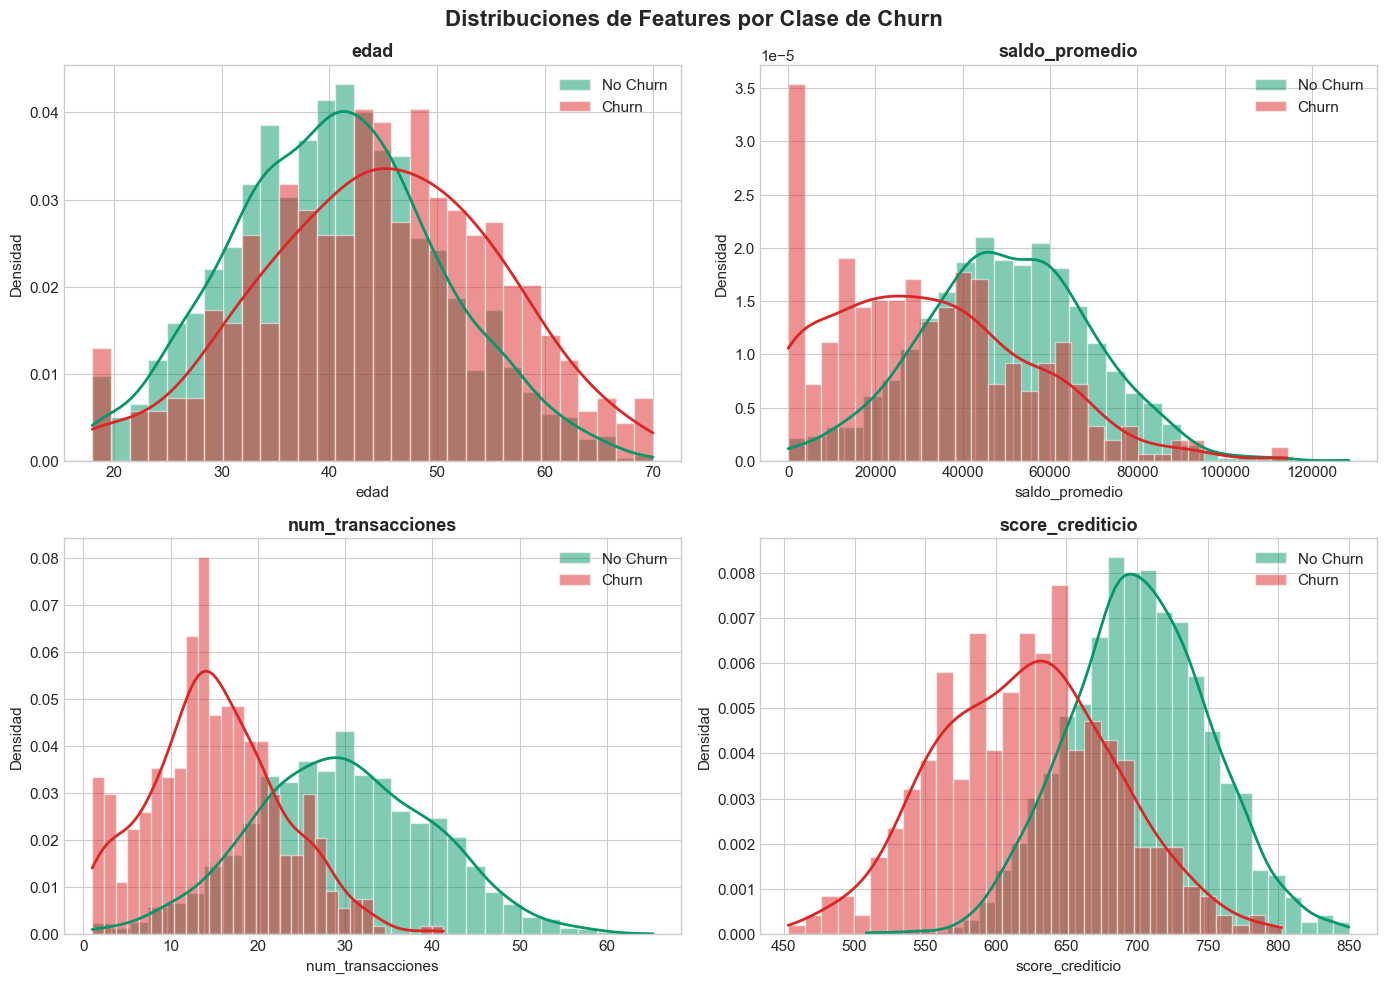


💡 Interpretación:
   - Las distribuciones muestran solapamiento entre clases (problema NO linealmente separable)
   - GaussianNB asume que cada feature sigue una distribución normal por clase
   - Los histogramas nos permiten verificar visualmente si esta asunción es razonable


In [4]:
# Visualización de distribuciones por clase
features = ['edad', 'saldo_promedio', 'num_transacciones', 'score_crediticio']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Distribuciones de Features por Clase de Churn', fontsize=16, fontweight='bold')

for idx, feature in enumerate(features):
    ax = axes[idx // 2, idx % 2]
    
    # Histogramas superpuestos
    for label, color, name in [(0, COLORS['success'], 'No Churn'), (1, COLORS['danger'], 'Churn')]:
        data = df_churn[df_churn['churn'] == label][feature]
        ax.hist(data, bins=30, alpha=0.5, color=color, label=name, density=True, edgecolor='white')
        
        # Superponer curva KDE
        x_range = np.linspace(data.min(), data.max(), 100)
        kde = stats.gaussian_kde(data)
        ax.plot(x_range, kde(x_range), color=color, linewidth=2)
    
    ax.set_title(f'{feature}', fontsize=13, fontweight='bold')
    ax.set_xlabel(feature)
    ax.set_ylabel('Densidad')
    ax.legend()

plt.tight_layout()
plt.show()

print("\n💡 Interpretación:")
print("   - Las distribuciones muestran solapamiento entre clases (problema NO linealmente separable)")
print("   - GaussianNB asume que cada feature sigue una distribución normal por clase")
print("   - Los histogramas nos permiten verificar visualmente si esta asunción es razonable")

### 1.3 Entrenamiento y Evaluación de GaussianNB

El flujo estándar de trabajo con cualquier clasificador de Scikit-Learn sigue estos pasos:

1. **Separar** features ($X$) y target ($y$)
2. **Dividir** en train/test (estratificado para preservar las proporciones de clase)
3. **Instanciar** el modelo
4. **Entrenar** con `.fit(X_train, y_train)`
5. **Predecir** con `.predict(X_test)` y/o `.predict_proba(X_test)`
6. **Evaluar** con métricas apropiadas

In [5]:
# Paso 1: Separar features y target
X_churn = df_churn.drop('churn', axis=1).values
y_churn = df_churn['churn'].values
feature_names_churn = df_churn.drop('churn', axis=1).columns.tolist()

# Paso 2: División train/test (estratificada)
X_train, X_test, y_train, y_test = train_test_split(
    X_churn, y_churn, test_size=0.25, random_state=42, stratify=y_churn
)

print(f"📦 División de datos:")
print(f"   Train: {X_train.shape[0]} muestras ({y_train.mean():.1%} churn)")
print(f"   Test:  {X_test.shape[0]} muestras ({y_test.mean():.1%} churn)")

📦 División de datos:
   Train: 1500 muestras (20.0% churn)
   Test:  500 muestras (20.0% churn)


In [6]:
# Paso 3-4: Instanciar y entrenar GaussianNB
gnb = GaussianNB()

# Medir tiempo de entrenamiento
t_start = time.time()
gnb.fit(X_train, y_train)
t_train = time.time() - t_start

# Paso 5: Predicciones
t_start = time.time()
y_pred = gnb.predict(X_test)
y_proba = gnb.predict_proba(X_test)[:, 1]  # Probabilidad de la clase positiva (churn)
t_pred = time.time() - t_start

print(f"⏱️  Tiempo de entrenamiento: {t_train*1000:.2f} ms")
print(f"⏱️  Tiempo de predicción:    {t_pred*1000:.2f} ms")
print(f"\n📊 Reporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

⏱️  Tiempo de entrenamiento: 2.10 ms
⏱️  Tiempo de predicción:    1.90 ms

📊 Reporte de Clasificación:
              precision    recall  f1-score   support

    No Churn       0.96      0.97      0.97       400
       Churn       0.87      0.85      0.86       100

    accuracy                           0.94       500
   macro avg       0.92      0.91      0.91       500
weighted avg       0.94      0.94      0.94       500



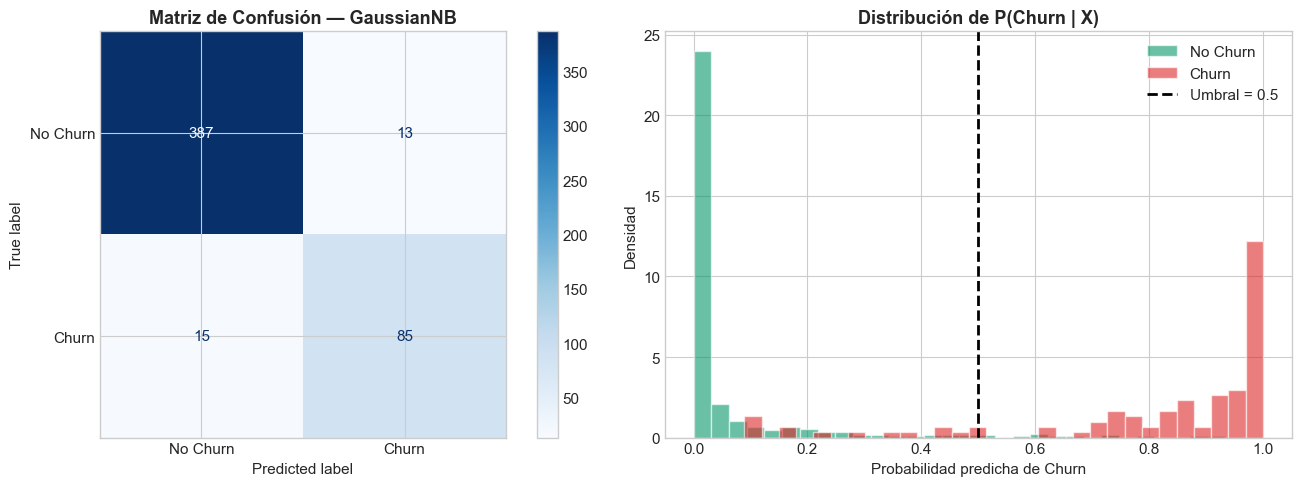


💡 Interpretación:
   - La matriz de confusión muestra los Verdaderos Positivos (TP), Falsos Positivos (FP),
     Verdaderos Negativos (TN) y Falsos Negativos (FN).
   - El histograma de probabilidades muestra cómo el modelo separa las clases.
   - Un modelo perfecto tendría los histogramas completamente separados en 0 y 1.


In [7]:
# Paso 6: Matriz de Confusión visual
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de confusión
ConfusionMatrixDisplay.from_estimator(
    gnb, X_test, y_test, 
    display_labels=['No Churn', 'Churn'],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title('Matriz de Confusión — GaussianNB', fontsize=13, fontweight='bold')

# Distribución de probabilidades predichas
for label, color, name in [(0, COLORS['success'], 'No Churn'), (1, COLORS['danger'], 'Churn')]:
    mask = y_test == label
    axes[1].hist(y_proba[mask], bins=30, alpha=0.6, color=color, label=name, density=True, edgecolor='white')

axes[1].axvline(x=0.5, color='black', linestyle='--', linewidth=2, label='Umbral = 0.5')
axes[1].set_title('Distribución de P(Churn | X)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Probabilidad predicha de Churn')
axes[1].set_ylabel('Densidad')
axes[1].legend()

plt.tight_layout()
plt.show()

print("\n💡 Interpretación:")
print("   - La matriz de confusión muestra los Verdaderos Positivos (TP), Falsos Positivos (FP),")
print("     Verdaderos Negativos (TN) y Falsos Negativos (FN).")
print("   - El histograma de probabilidades muestra cómo el modelo separa las clases.")
print("   - Un modelo perfecto tendría los histogramas completamente separados en 0 y 1.")

### 1.4 Inspección de los Parámetros Aprendidos

Una ventaja enorme de Naive Bayes es su **interpretabilidad**: podemos inspeccionar exactamente qué aprendió el modelo (las medias $\mu_{kj}$ y varianzas $\sigma_{kj}^2$ de cada feature para cada clase).

In [8]:
# Inspección de parámetros aprendidos por GaussianNB
print("🔍 Parámetros aprendidos por GaussianNB:")
print(f"\n   Clases detectadas: {gnb.classes_}")
print(f"   Prior de cada clase: {gnb.class_prior_}")
print(f"   Conteo por clase:   {gnb.class_count_}")

# Tabla de medias por feature y clase
df_medias = pd.DataFrame(
    gnb.theta_, 
    columns=feature_names_churn,
    index=['No Churn (μ)', 'Churn (μ)']
).round(2)

df_varianzas = pd.DataFrame(
    gnb.var_, 
    columns=feature_names_churn,
    index=['No Churn (σ²)', 'Churn (σ²)']
).round(2)

print("\n📊 Medias condicionales (θ = μ_kj):")
display(df_medias)
print("\n📊 Varianzas condicionales (σ²_kj):")
display(df_varianzas)

print("\n💡 Interpretación para el negocio:")
print("   Comparando las medias entre clases, podemos identificar los factores de riesgo de churn:")
print("   - Clientes que hacen churn tienden a tener MENOR saldo, MENOS transacciones y MENOR score crediticio")
print("   - Estos insights son directamente accionables para el equipo de retención")

🔍 Parámetros aprendidos por GaussianNB:

   Clases detectadas: [0 1]
   Prior de cada clase: [0.8 0.2]
   Conteo por clase:   [1200.  300.]

📊 Medias condicionales (θ = μ_kj):


,edad,saldo_promedio,num_productos,meses_antiguedad,num_transacciones,score_crediticio,salario_estimado
No Churn (μ),40.35,49846.10,2.05,47.72,29.95,701.75,59389.56
Churn (μ),43.99,32619.95,1.67,24.94,15.22,620.30,51270.69



📊 Varianzas condicionales (σ²_kj):


,edad,saldo_promedio,num_productos,meses_antiguedad,num_transacciones,score_crediticio,salario_estimado
No Churn (σ²),95.53,3.794810e+08,1.29,383.56,110.23,2482.68,3.702661e+08
Churn (σ²),118.26,4.926190e+08,1.13,183.74,58.29,3774.08,3.067805e+08



💡 Interpretación para el negocio:
   Comparando las medias entre clases, podemos identificar los factores de riesgo de churn:
   - Clientes que hacen churn tienden a tener MENOR saldo, MENOS transacciones y MENOR score crediticio
   - Estos insights son directamente accionables para el equipo de retención


### 1.5 Validación Cruzada y el Efecto de `var_smoothing`

`var_smoothing` es el único hiperparámetro de `GaussianNB`. Suma una fracción de la mayor varianza a todas las varianzas, actuando como un **regularizador** que previene inestabilidad numérica:

$$\sigma_{kj}^2 \leftarrow \sigma_{kj}^2 + \epsilon \cdot \max(\text{todas las varianzas})$$

donde $\epsilon$ es `var_smoothing` (por defecto $10^{-9}$).

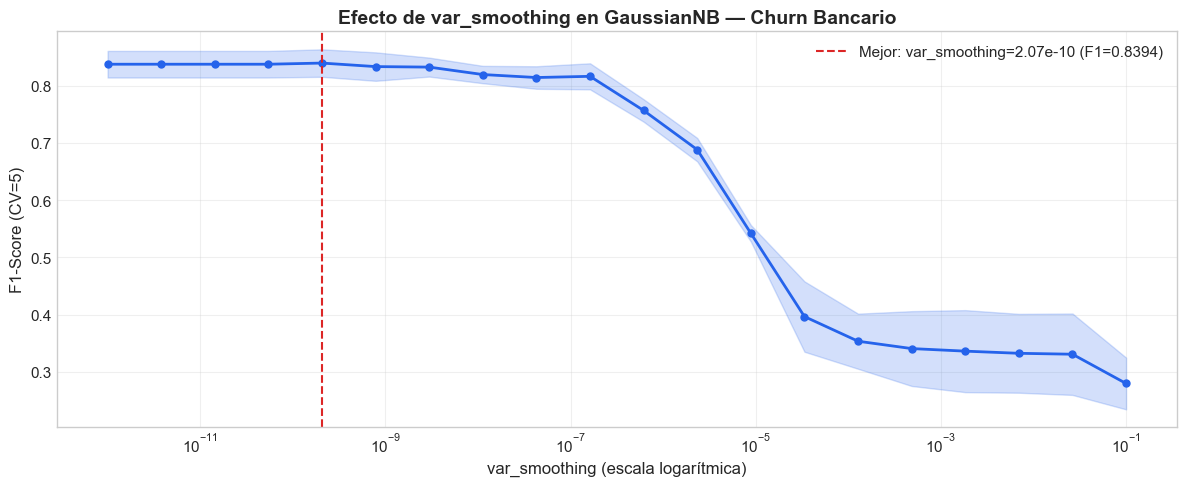


🏆 Mejor var_smoothing: 2.07e-10
   F1-Score CV: 0.8394 ± 0.0240


In [9]:
# Efecto de var_smoothing con validación cruzada
smoothing_values = np.logspace(-12, -1, 20)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_means = []
cv_stds = []

for vs in smoothing_values:
    model = GaussianNB(var_smoothing=vs)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

cv_means = np.array(cv_means)
cv_stds = np.array(cv_stds)

# Visualización
fig, ax = plt.subplots(figsize=(12, 5))
ax.semilogx(smoothing_values, cv_means, 'o-', color=COLORS['primary'], linewidth=2, markersize=5)
ax.fill_between(smoothing_values, cv_means - cv_stds, cv_means + cv_stds, alpha=0.2, color=COLORS['primary'])

best_idx = np.argmax(cv_means)
ax.axvline(smoothing_values[best_idx], color=COLORS['danger'], linestyle='--', linewidth=1.5,
           label=f'Mejor: var_smoothing={smoothing_values[best_idx]:.2e} (F1={cv_means[best_idx]:.4f})')

ax.set_xlabel('var_smoothing (escala logarítmica)', fontsize=12)
ax.set_ylabel('F1-Score (CV=5)', fontsize=12)
ax.set_title('Efecto de var_smoothing en GaussianNB — Churn Bancario', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n🏆 Mejor var_smoothing: {smoothing_values[best_idx]:.2e}")
print(f"   F1-Score CV: {cv_means[best_idx]:.4f} ± {cv_stds[best_idx]:.4f}")

---

## 2. Caso Práctico: MultinomialNB — Detección de Spam en Emails

### 📧 Contexto de Negocio

Una empresa de correo electrónico necesita clasificar automáticamente los emails entrantes como **spam** o **no spam** (ham). Este es uno de los casos de uso **más exitosos** de Naive Bayes en la industria.

**¿Por qué MultinomialNB aquí?**
- Los datos son **conteos de palabras** (representación *Bag-of-Words*) → Distribución Multinomial
- Los filtros de spam necesitan ser **extremadamente rápidos** (millones de emails por segundo)
- Naive Bayes multinomial es el **estándar de la industria** para clasificación de texto

### 📐 Recordatorio Teórico (Breve)

`MultinomialNB` modela la probabilidad de cada palabra $w_j$ en la clase $c_k$ como:

$$\hat{\theta}_{kj} = \frac{N_{kj} + \alpha}{N_k + \alpha V}$$

donde:
- $N_{kj}$ = Conteo total de la palabra $w_j$ en todos los documentos de clase $c_k$
- $N_k$ = Total de palabras en la clase $c_k$
- $V$ = Tamaño del vocabulario
- $\alpha$ = Parámetro de suavizado de Laplace (evita probabilidades de cero)

**En español práctico:** El modelo aprende qué palabras son más frecuentes en spam vs. ham, y clasifica un email nuevo según las palabras que contiene.

### 2.1 Generación del Dataset Sintético de Emails

In [10]:
def generar_dataset_emails(n_samples=1000, random_state=42):
    """
    Genera un dataset sintético de emails para clasificación spam/ham.
    Los emails se generan combinando frases típicas de cada categoría.
    """
    np.random.seed(random_state)
    
    # Vocabulario y frases típicas de SPAM
    spam_phrases = [
        "ganar dinero rapido facil gratis",
        "oferta especial descuento increible solo hoy",
        "felicidades has ganado premio loteria millones",
        "compra ahora oferta limitada urgente actua ya",
        "trabaja desde casa gana miles dolares semanal",
        "credito aprobado sin requisitos solicita prestamo",
        "pierde peso rapido pastillas milagrosas dieta",
        "click aqui enlace gratis regalo descarga",
        "inversion garantizada retorno ganancias bitcoin criptomoneda",
        "herencia millonaria transferencia banco nigeria principe",
        "viagra cialis farmacia online descuento medicamentos",
        "urgente cuenta suspendida verificar contrasena datos",
        "ganador sorteo premio exclusivo reclama ahora",
        "oportunidad unica negocio multinivel comision referidos",
        "replica relojes marca lujo precio bajo"
    ]
    
    # Vocabulario y frases típicas de HAM (emails legítimos)
    ham_phrases = [
        "reunion equipo proyecto martes oficina sala conferencias",
        "adjunto reporte trimestral ventas analisis resultados",
        "confirmo asistencia evento corporativo viernes proximo",
        "necesito revision documento propuesta cliente",
        "actualizacion sprint desarrollo software equipo ingenieria",
        "agenda llamada discutir presupuesto departamento",
        "saludos familia espero esten bien vacaciones fin semana",
        "gracias informacion enviada voy revisar comentarios",
        "recordatorio pago factura servicio mensual",
        "invitacion cumpleanos celebracion sabado casa amigos",
        "solicitud vacaciones aprobada recursos humanos",
        "minuta reunion decisiones acuerdos proximos pasos",
        "consulta disponibilidad horario entrevista candidato",
        "compartir articulo interesante tecnologia innovacion",
        "coordinacion entrega pedido cliente fecha limite"
    ]
    
    emails = []
    labels = []
    
    n_spam = int(n_samples * 0.35)  # 35% spam (proporción realista)
    n_ham = n_samples - n_spam
    
    # Generar emails de spam
    for _ in range(n_spam):
        n_phrases = np.random.randint(2, 5)
        selected = np.random.choice(spam_phrases, n_phrases, replace=True)
        # Agregar algo de ruido (palabras de ham) para hacerlo más realista
        if np.random.random() < 0.2:
            selected = np.append(selected, np.random.choice(ham_phrases, 1))
        email = ' '.join(selected)
        emails.append(email)
        labels.append(1)  # 1 = spam
    
    # Generar emails legítimos (ham)
    for _ in range(n_ham):
        n_phrases = np.random.randint(2, 5)
        selected = np.random.choice(ham_phrases, n_phrases, replace=True)
        # Agregar algo de ruido (palabras de spam)
        if np.random.random() < 0.1:
            selected = np.append(selected, np.random.choice(spam_phrases, 1))
        email = ' '.join(selected)
        emails.append(email)
        labels.append(0)  # 0 = ham
    
    # Mezclar
    indices = np.random.permutation(len(emails))
    emails = [emails[i] for i in indices]
    labels = [labels[i] for i in indices]
    
    return emails, np.array(labels)

# Generar dataset
emails, y_spam = generar_dataset_emails(n_samples=1500)

print(f"📧 Dataset de Emails")
print(f"   Total emails: {len(emails)}")
print(f"   Spam: {sum(y_spam)} ({sum(y_spam)/len(y_spam):.1%})")
print(f"   Ham:  {sum(y_spam == 0)} ({sum(y_spam == 0)/len(y_spam):.1%})")
print(f"\n📝 Ejemplo de email SPAM:")
print(f"   '{emails[np.where(y_spam == 1)[0][0]]}'")
print(f"\n📝 Ejemplo de email HAM:")
print(f"   '{emails[np.where(y_spam == 0)[0][0]]}'")

📧 Dataset de Emails
   Total emails: 1500
   Spam: 525 (35.0%)
   Ham:  975 (65.0%)

📝 Ejemplo de email SPAM:
   'felicidades has ganado premio loteria millones click aqui enlace gratis regalo descarga'

📝 Ejemplo de email HAM:
   'coordinacion entrega pedido cliente fecha limite reunion equipo proyecto martes oficina sala conferencias reunion equipo proyecto martes oficina sala conferencias'


### 2.2 Pipeline NLP: Vectorización + MultinomialNB

Para usar Naive Bayes con texto, necesitamos convertir los emails en vectores numéricos. Hay dos estrategias principales:

| Vectorizador | Representación | Cuándo usarlo |
| :--- | :--- | :--- |
| `CountVectorizer` | Conteo de ocurrencias de cada palabra | Textos cortos, cuando la frecuencia absoluta importa |
| `TfidfVectorizer` | TF-IDF (Term Frequency × Inverse Document Frequency) | Textos largos, para penalizar palabras muy comunes |

Usaremos un **Pipeline** para encadenar la vectorización con el clasificador, lo cual es una **mejor práctica profesional** que evita fugas de datos (*data leakage*).

In [11]:
# División train/test
emails_train, emails_test, y_spam_train, y_spam_test = train_test_split(
    emails, y_spam, test_size=0.25, random_state=42, stratify=y_spam
)

# Pipeline 1: CountVectorizer + MultinomialNB
pipe_count = Pipeline([
    ('vectorizer', CountVectorizer(max_features=5000, stop_words=None)),
    ('clf', MultinomialNB(alpha=1.0))
])

# Pipeline 2: TfidfVectorizer + MultinomialNB
pipe_tfidf = Pipeline([
    ('vectorizer', TfidfVectorizer(max_features=5000, stop_words=None)),
    ('clf', MultinomialNB(alpha=1.0))
])

# Entrenar ambos pipelines
pipe_count.fit(emails_train, y_spam_train)
pipe_tfidf.fit(emails_train, y_spam_train)

# Evaluar
results_nlp = {}
for name, pipe in [('CountVectorizer + MNB', pipe_count), ('TfidfVectorizer + MNB', pipe_tfidf)]:
    y_pred = pipe.predict(emails_test)
    y_proba = pipe.predict_proba(emails_test)[:, 1]
    results_nlp[name] = {
        'Accuracy': accuracy_score(y_spam_test, y_pred),
        'Precision': precision_score(y_spam_test, y_pred),
        'Recall': recall_score(y_spam_test, y_pred),
        'F1': f1_score(y_spam_test, y_pred),
        'ROC-AUC': roc_auc_score(y_spam_test, y_proba)
    }

df_results_nlp = pd.DataFrame(results_nlp).T
print("📊 Comparación de Pipelines NLP:")
display(df_results_nlp.round(4))

📊 Comparación de Pipelines NLP:


,Accuracy,Precision,Recall,F1,ROC-AUC
CountVectorizer + MNB,1.0,1.0,1.0,1.0,1.0
TfidfVectorizer + MNB,1.0,1.0,1.0,1.0,1.0


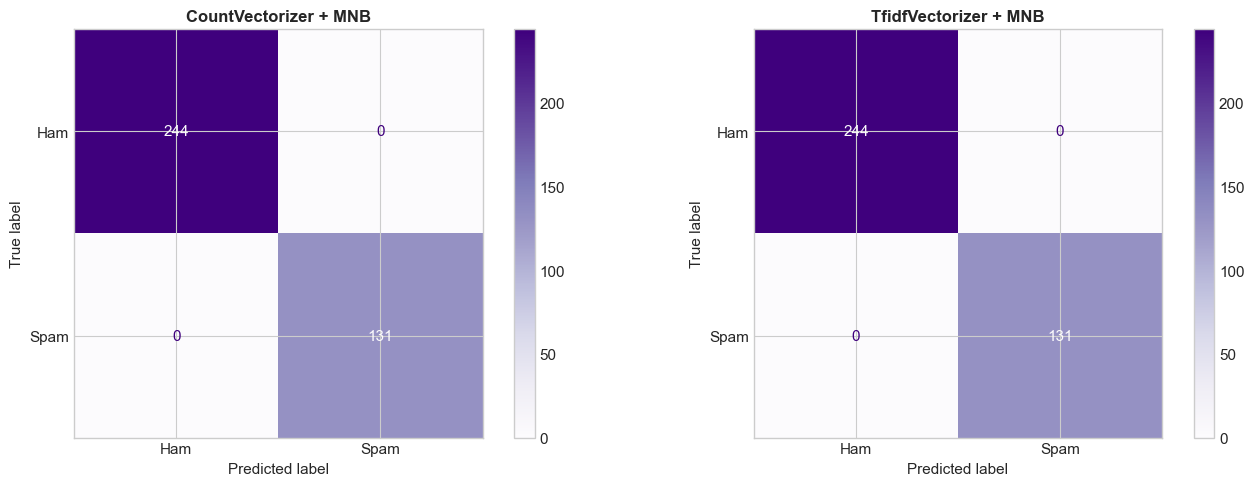

In [12]:
# Visualización: Matrices de confusión lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (name, pipe) in enumerate([('CountVectorizer + MNB', pipe_count), ('TfidfVectorizer + MNB', pipe_tfidf)]):
    ConfusionMatrixDisplay.from_estimator(
        pipe, emails_test, y_spam_test,
        display_labels=['Ham', 'Spam'],
        cmap='Purples', ax=axes[idx]
    )
    axes[idx].set_title(f'{name}', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 2.3 Análisis de las Palabras Más Informativas

Una ventaja clave de MultinomialNB es que podemos extraer las **palabras más indicativas** de spam y ham, lo cual es invaluable para los analistas de negocio.

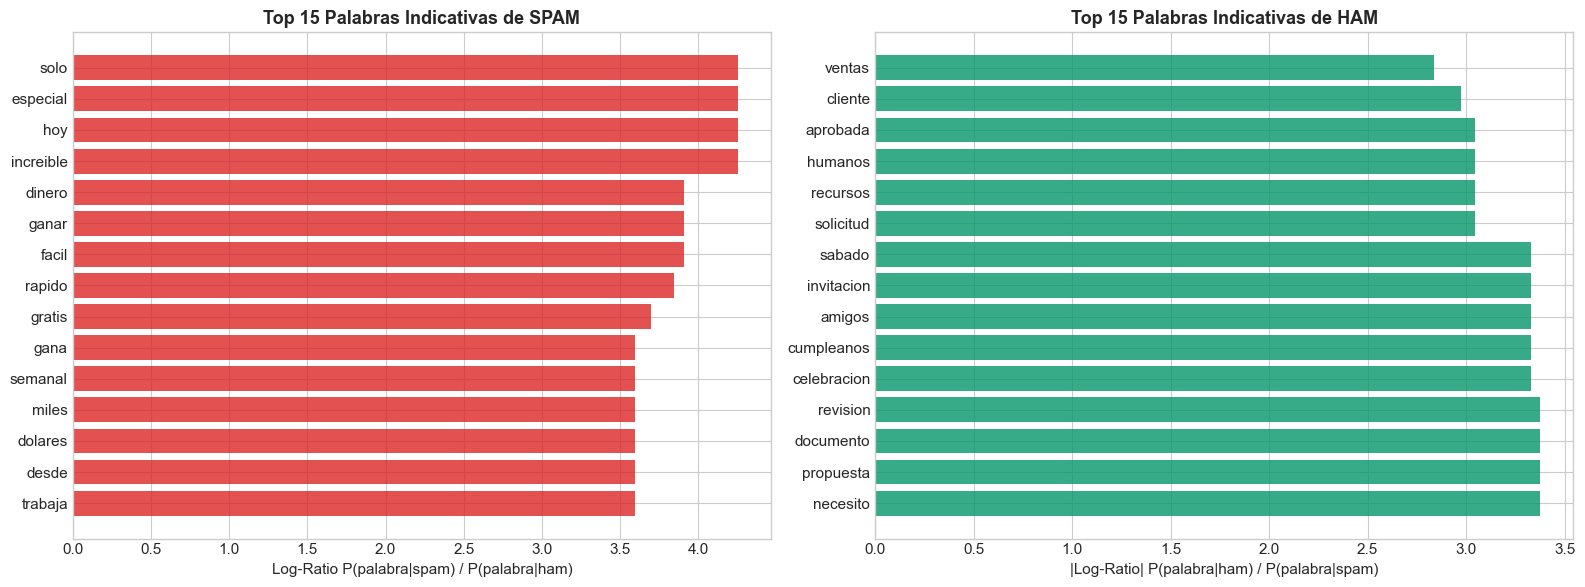


💡 Interpretación para el negocio:
   - Palabras como 'gratis', 'oferta', 'ganar' son fuertes indicadores de spam
   - Palabras como 'reunion', 'proyecto', 'equipo' son fuertes indicadores de email legítimo
   - Estos insights permiten al equipo de seguridad crear reglas de filtrado complementarias


In [13]:
# Extraer las palabras más informativas
vectorizer = pipe_count.named_steps['vectorizer']
clf = pipe_count.named_steps['clf']

feature_names = vectorizer.get_feature_names_out()

# Log-probabilidades de cada palabra por clase
log_prob_ham = clf.feature_log_prob_[0]   # Clase 0 (ham)
log_prob_spam = clf.feature_log_prob_[1]  # Clase 1 (spam)

# Ratio log-probabilidad: palabras más indicativas de spam vs ham
log_ratio = log_prob_spam - log_prob_ham

# Top 15 palabras más indicativas de SPAM
top_spam_idx = np.argsort(log_ratio)[-15:]
# Top 15 palabras más indicativas de HAM
top_ham_idx = np.argsort(log_ratio)[:15]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Palabras más indicativas de SPAM
axes[0].barh(
    [feature_names[i] for i in top_spam_idx],
    log_ratio[top_spam_idx],
    color=COLORS['danger'], alpha=0.8
)
axes[0].set_title('Top 15 Palabras Indicativas de SPAM', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Log-Ratio P(palabra|spam) / P(palabra|ham)')

# Palabras más indicativas de HAM
axes[1].barh(
    [feature_names[i] for i in top_ham_idx],
    np.abs(log_ratio[top_ham_idx]),
    color=COLORS['success'], alpha=0.8
)
axes[1].set_title('Top 15 Palabras Indicativas de HAM', fontsize=13, fontweight='bold')
axes[1].set_xlabel('|Log-Ratio| P(palabra|ham) / P(palabra|spam)')

plt.tight_layout()
plt.show()

print("\n💡 Interpretación para el negocio:")
print("   - Palabras como 'gratis', 'oferta', 'ganar' son fuertes indicadores de spam")
print("   - Palabras como 'reunion', 'proyecto', 'equipo' son fuertes indicadores de email legítimo")
print("   - Estos insights permiten al equipo de seguridad crear reglas de filtrado complementarias")

### 2.4 Optimización del Hiperparámetro `alpha` con GridSearchCV

El parámetro `alpha` controla el **suavizado de Laplace**: 
- $\alpha = 0$ → Sin suavizado (riesgo de probabilidades cero)
- $\alpha = 1$ → Suavizado de Laplace estándar
- $\alpha > 1$ → Suavizado más agresivo (sesga hacia probabilidades uniformes)

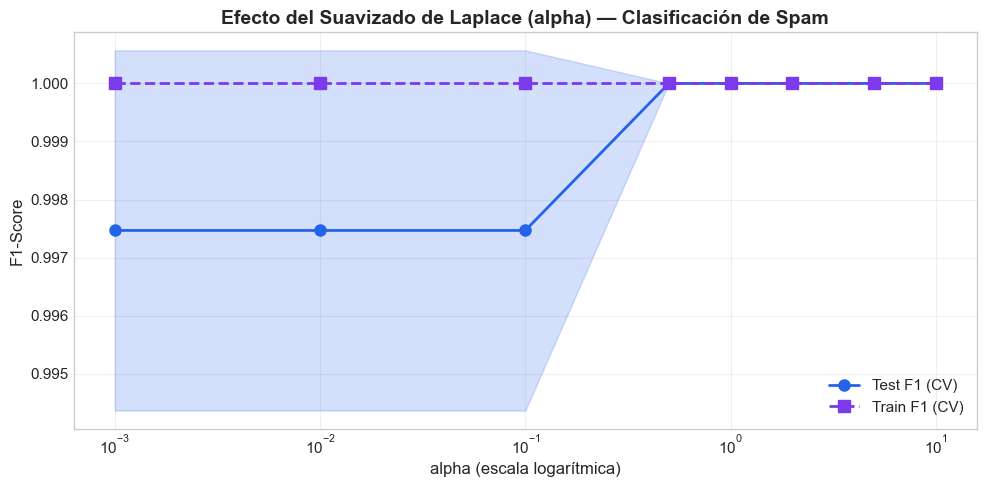


🏆 Mejor alpha: 0.5
   F1-Score CV: 1.0000


In [14]:
# GridSearchCV para encontrar el mejor alpha
param_grid = {
    'clf__alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
}

grid_search = GridSearchCV(
    pipe_count, param_grid, 
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring='f1', n_jobs=-1, return_train_score=True
)
grid_search.fit(emails_train, y_spam_train)

# Resultados
results_df = pd.DataFrame(grid_search.cv_results_)

fig, ax = plt.subplots(figsize=(10, 5))
alphas = [p['clf__alpha'] for p in results_df['params']]

ax.semilogx(alphas, results_df['mean_test_score'], 'o-', color=COLORS['primary'], 
            linewidth=2, label='Test F1 (CV)', markersize=8)
ax.fill_between(alphas, 
                results_df['mean_test_score'] - results_df['std_test_score'],
                results_df['mean_test_score'] + results_df['std_test_score'],
                alpha=0.2, color=COLORS['primary'])

ax.semilogx(alphas, results_df['mean_train_score'], 's--', color=COLORS['secondary'], 
            linewidth=2, label='Train F1 (CV)', markersize=8)

ax.set_xlabel('alpha (escala logarítmica)', fontsize=12)
ax.set_ylabel('F1-Score', fontsize=12)
ax.set_title('Efecto del Suavizado de Laplace (alpha) — Clasificación de Spam', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n🏆 Mejor alpha: {grid_search.best_params_['clf__alpha']}")
print(f"   F1-Score CV: {grid_search.best_score_:.4f}")

---

## 3. Caso Práctico: BernoulliNB — Detección de Fraude en Transacciones

### 💳 Contexto de Negocio

Un banco necesita detectar transacciones fraudulentas en tiempo real. Las transacciones se caracterizan por **indicadores binarios** (sí/no) que representan patrones sospechosos.

**¿Por qué BernoulliNB aquí?**
- Las features son **binarias** (presencia/ausencia de indicadores de riesgo) → Distribución de Bernoulli
- `BernoulliNB` **penaliza explícitamente la ausencia** de una feature, a diferencia de `MultinomialNB`
- Cuando un indicador de fraude está **ausente**, eso es evidencia de que la transacción es legítima

### 📐 Diferencia Clave entre BernoulliNB y MultinomialNB

| Aspecto | MultinomialNB | BernoulliNB |
| :--- | :--- | :--- |
| Tipo de dato | Conteos ($x_j \geq 0$) | Binario ($x_j \in \{0, 1\}$) |
| Feature ausente ($x_j = 0$) | **Ignora** (no contribuye al log-odds) | **Penaliza explícitamente** con $\ln(1 - \theta_{kj})$ |
| Fórmula | $\sum_j x_j \ln \theta_{kj}$ | $\sum_j [x_j \ln \theta_{kj} + (1-x_j) \ln(1-\theta_{kj})]$ |
| Caso de uso | Documentos largos | Textos cortos, features binarias |

In [15]:
def generar_dataset_fraude(n_samples=3000, random_state=42):
    """
    Genera un dataset sintético de detección de fraude con features binarias.
    """
    np.random.seed(random_state)
    
    feature_names = [
        'transaccion_internacional', 'hora_inusual', 'monto_alto',
        'comercio_nuevo', 'tarjeta_no_presente', 'ubicacion_diferente',
        'multiples_intentos', 'cambio_datos_reciente', 'velocidad_gasto',
        'dispositivo_nuevo'
    ]
    
    # Probabilidades de que cada indicador sea 1, según la clase
    p_legit = [0.15, 0.10, 0.05, 0.30, 0.20, 0.08, 0.02, 0.05, 0.03, 0.10]
    p_fraud = [0.60, 0.55, 0.50, 0.65, 0.70, 0.55, 0.40, 0.35, 0.50, 0.55]
    
    n_fraud = int(n_samples * 0.05)  # Solo 5% de fraude (muy desbalanceado, realista)
    n_legit = n_samples - n_fraud
    
    X_legit = np.column_stack([np.random.binomial(1, p, n_legit) for p in p_legit])
    X_fraud = np.column_stack([np.random.binomial(1, p, n_fraud) for p in p_fraud])
    
    X = np.vstack([X_legit, X_fraud])
    y = np.concatenate([np.zeros(n_legit), np.ones(n_fraud)]).astype(int)
    
    idx = np.random.permutation(len(y))
    df = pd.DataFrame(X[idx], columns=feature_names)
    df['fraude'] = y[idx]
    
    return df

# Generar dataset
df_fraude = generar_dataset_fraude(n_samples=3000)

print(f"💳 Dataset de Detección de Fraude")
print(f"   Dimensiones: {df_fraude.shape}")
print(f"   Tasa de fraude: {df_fraude['fraude'].mean():.1%} (altamente desbalanceado)")
print(f"\n📊 Distribución:")
print(f"   {df_fraude['fraude'].value_counts().to_dict()}")
print()
df_fraude.head()

💳 Dataset de Detección de Fraude
   Dimensiones: (3000, 11)
   Tasa de fraude: 5.0% (altamente desbalanceado)

📊 Distribución:
   {0: 2850, 1: 150}



,transaccion_internacional,hora_inusual,monto_alto,comercio_nuevo,tarjeta_no_presente,ubicacion_diferente,multiples_intentos,cambio_datos_reciente,velocidad_gasto,dispositivo_nuevo,fraude
0,0,0,0,1,0,1,0,0,1,0,0
1,0,0,0,1,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0
4,0,1,0,1,1,0,0,0,0,1,0


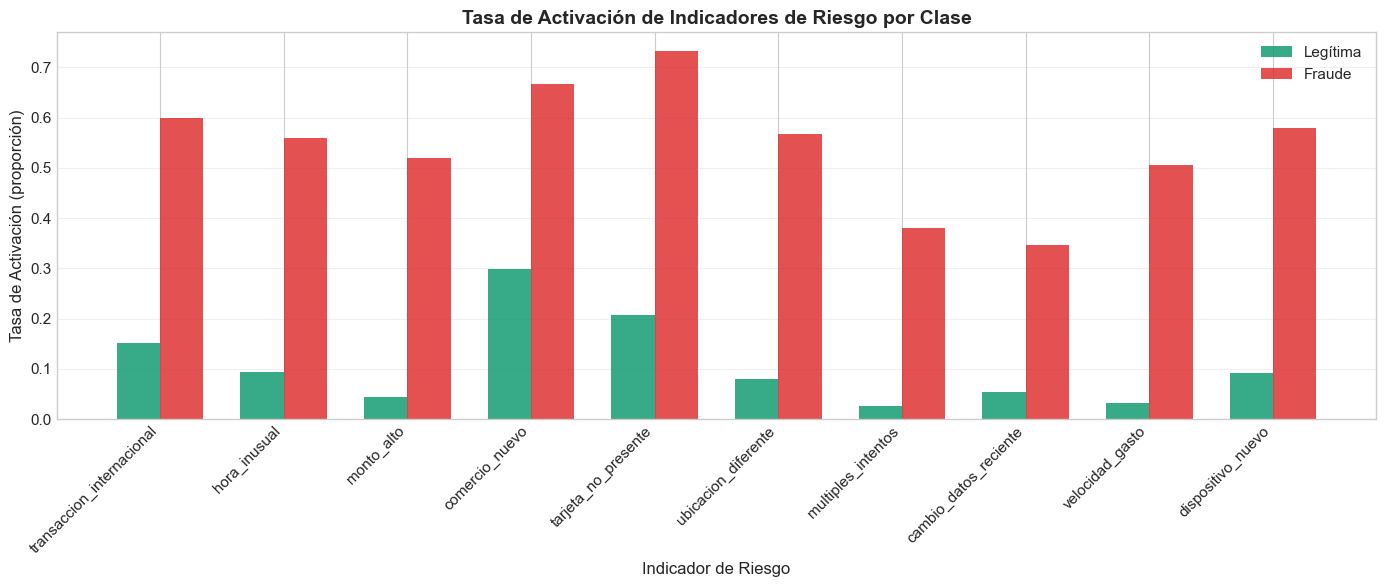


💡 Observación clave:
   Los indicadores de riesgo se activan con mucha más frecuencia en transacciones fraudulentas.
   BernoulliNB captura esto explícitamente: la AUSENCIA de estos indicadores es evidencia CONTRA fraude.


In [16]:
# Visualizar la tasa de activación de cada indicador por clase
feature_cols = df_fraude.columns[:-1]

rates_legit = df_fraude[df_fraude['fraude'] == 0][feature_cols].mean()
rates_fraud = df_fraude[df_fraude['fraude'] == 1][feature_cols].mean()

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(feature_cols))
width = 0.35

bars1 = ax.bar(x - width/2, rates_legit, width, label='Legítima', color=COLORS['success'], alpha=0.8)
bars2 = ax.bar(x + width/2, rates_fraud, width, label='Fraude', color=COLORS['danger'], alpha=0.8)

ax.set_xlabel('Indicador de Riesgo', fontsize=12)
ax.set_ylabel('Tasa de Activación (proporción)', fontsize=12)
ax.set_title('Tasa de Activación de Indicadores de Riesgo por Clase', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(feature_cols, rotation=45, ha='right')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n💡 Observación clave:")
print("   Los indicadores de riesgo se activan con mucha más frecuencia en transacciones fraudulentas.")
print("   BernoulliNB captura esto explícitamente: la AUSENCIA de estos indicadores es evidencia CONTRA fraude.")

In [17]:
# Entrenamiento y evaluación de BernoulliNB
X_fraud = df_fraude.drop('fraude', axis=1).values
y_fraud = df_fraude['fraude'].values

X_fr_train, X_fr_test, y_fr_train, y_fr_test = train_test_split(
    X_fraud, y_fraud, test_size=0.25, random_state=42, stratify=y_fraud
)

# BernoulliNB
bnb = BernoulliNB(alpha=1.0)
bnb.fit(X_fr_train, y_fr_train)

y_fr_pred = bnb.predict(X_fr_test)
y_fr_proba = bnb.predict_proba(X_fr_test)[:, 1]

# Comparar con MultinomialNB (para demostrar la diferencia)
mnb_fraud = MultinomialNB(alpha=1.0)
mnb_fraud.fit(X_fr_train, y_fr_train)
y_fr_pred_mnb = mnb_fraud.predict(X_fr_test)
y_fr_proba_mnb = mnb_fraud.predict_proba(X_fr_test)[:, 1]

print("📊 Comparación BernoulliNB vs MultinomialNB en datos binarios:")
print("\n" + "="*60)
print("BERNOULLI NB (diseñado para datos binarios):")
print("="*60)
print(classification_report(y_fr_test, y_fr_pred, target_names=['Legítima', 'Fraude']))

print("="*60)
print("MULTINOMIAL NB (no óptimo para datos binarios):")
print("="*60)
print(classification_report(y_fr_test, y_fr_pred_mnb, target_names=['Legítima', 'Fraude']))

print("\n💡 Nota importante:")
print("   En datos binarios, BernoulliNB generalmente supera a MultinomialNB porque")
print("   modela explícitamente la AUSENCIA de indicadores como evidencia.")
print("   MultinomialNB simplemente ignora los ceros, perdiendo información valiosa.")

📊 Comparación BernoulliNB vs MultinomialNB en datos binarios:

BERNOULLI NB (diseñado para datos binarios):
              precision    recall  f1-score   support

    Legítima       0.99      1.00      0.99       713
      Fraude       0.94      0.81      0.87        37

    accuracy                           0.99       750
   macro avg       0.96      0.90      0.93       750
weighted avg       0.99      0.99      0.99       750

MULTINOMIAL NB (no óptimo para datos binarios):
              precision    recall  f1-score   support

    Legítima       0.95      1.00      0.98       713
      Fraude       1.00      0.03      0.05        37

    accuracy                           0.95       750
   macro avg       0.98      0.51      0.51       750
weighted avg       0.95      0.95      0.93       750


💡 Nota importante:
   En datos binarios, BernoulliNB generalmente supera a MultinomialNB porque
   modela explícitamente la AUSENCIA de indicadores como evidencia.
   MultinomialNB simpleme

---

## 4. Caso Práctico: CategoricalNB — Aprobación de Crédito

### 🏛️ Contexto de Negocio

Un banco quiere automatizar la **pre-aprobación de créditos** basándose en características demográficas y financieras del solicitante, todas ellas **categóricas** (nivel educativo, tipo de empleo, rango de ingreso, etc.).

**¿Por qué CategoricalNB aquí?**
- Las features son **categóricas nominales** (sin orden numérico) → Distribución Categórica
- Cada feature $X_j$ puede tener un número diferente de categorías $K_j$
- No necesitamos One-Hot Encoding (lo cual inflaría la dimensionalidad)

### 📐 Recordatorio Teórico (Breve)

`CategoricalNB` asume que cada feature $X_j$ sigue una distribución **Categórica** (Multinoulli) independiente:

$$P(X_j = v \mid Y = c_k) = \frac{\text{count}(X_j = v, Y = c_k) + \alpha}{\text{count}(Y = c_k) + \alpha \cdot K_j}$$

donde $K_j$ es el número de categorías de la feature $j$.

In [18]:
def generar_dataset_credito(n_samples=1500, random_state=42):
    """
    Genera un dataset sintético de aprobación de crédito con variables categóricas.
    """
    np.random.seed(random_state)
    
    niveles_educacion = ['Secundaria', 'Licenciatura', 'Maestría', 'Doctorado']
    tipos_empleo = ['Asalariado', 'Independiente', 'Empresario', 'Desempleado', 'Jubilado']
    rangos_ingreso = ['Bajo', 'Medio-Bajo', 'Medio', 'Medio-Alto', 'Alto']
    estados_civil = ['Soltero', 'Casado', 'Divorciado', 'Viudo']
    tipos_vivienda = ['Propia', 'Alquilada', 'Familiar', 'Hipoteca']
    historial_credito = ['Sin_historial', 'Malo', 'Regular', 'Bueno', 'Excelente']
    
    data = []
    
    for _ in range(n_samples):
        edu = np.random.choice(niveles_educacion, p=[0.3, 0.35, 0.25, 0.10])
        emp = np.random.choice(tipos_empleo, p=[0.40, 0.20, 0.15, 0.15, 0.10])
        ing = np.random.choice(rangos_ingreso, p=[0.15, 0.25, 0.30, 0.20, 0.10])
        ecivil = np.random.choice(estados_civil, p=[0.30, 0.40, 0.20, 0.10])
        viv = np.random.choice(tipos_vivienda, p=[0.25, 0.30, 0.20, 0.25])
        hist = np.random.choice(historial_credito, p=[0.15, 0.10, 0.25, 0.30, 0.20])
        
        score = 0.0
        score += {'Secundaria': 0, 'Licenciatura': 0.1, 'Maestría': 0.15, 'Doctorado': 0.2}[edu]
        score += {'Asalariado': 0.15, 'Independiente': 0.05, 'Empresario': 0.10, 'Desempleado': -0.3, 'Jubilado': 0.05}[emp]
        score += {'Bajo': -0.2, 'Medio-Bajo': -0.05, 'Medio': 0.1, 'Medio-Alto': 0.2, 'Alto': 0.3}[ing]
        score += {'Sin_historial': -0.1, 'Malo': -0.3, 'Regular': 0.0, 'Bueno': 0.2, 'Excelente': 0.3}[hist]
        score += {'Propia': 0.15, 'Alquilada': -0.05, 'Familiar': -0.1, 'Hipoteca': 0.1}[viv]
        
        prob_aprobacion = 1 / (1 + np.exp(-3 * score))
        aprobado = int(np.random.random() < prob_aprobacion)
        
        data.append([edu, emp, ing, ecivil, viv, hist, aprobado])
    
    df = pd.DataFrame(data, columns=[
        'educacion', 'empleo', 'ingreso', 'estado_civil', 'vivienda', 'historial_credito', 'aprobado'
    ])
    
    return df

# Generar dataset
df_credito = generar_dataset_credito(n_samples=1500)

print(f"🏛️ Dataset de Aprobación de Crédito")
print(f"   Dimensiones: {df_credito.shape}")
print(f"   Tasa de aprobación: {df_credito['aprobado'].mean():.1%}")
print()
df_credito.head(10)

🏛️ Dataset de Aprobación de Crédito
   Dimensiones: (1500, 7)
   Tasa de aprobación: 68.0%



,educacion,empleo,ingreso,estado_civil,vivienda,historial_credito,aprobado
0,Licenciatura,Jubilado,Medio-Alto,Casado,Propia,Malo,1
1,Maestría,Empresario,Medio-Alto,Soltero,Hipoteca,Excelente,1
2,Secundaria,Asalariado,Medio-Bajo,Casado,Alquilada,Regular,0
3,Secundaria,Asalariado,Medio-Bajo,Casado,Hipoteca,Malo,0
4,Licenciatura,Asalariado,Medio,Soltero,Propia,Excelente,0
5,Maestría,Asalariado,Bajo,Casado,Alquilada,Sin_historial,0
6,Secundaria,Jubilado,Medio-Bajo,Casado,Alquilada,Bueno,1
7,Secundaria,Jubilado,Medio-Alto,Viudo,Hipoteca,Bueno,0
8,Secundaria,Asalariado,Bajo,Casado,Alquilada,Regular,0
9,Licenciatura,Asalariado,Medio,Soltero,Hipoteca,Sin_historial,0


In [19]:
# CategoricalNB requiere codificación ordinal (enteros)
feature_cols_cred = df_credito.columns[:-1]
X_cred = df_credito[feature_cols_cred]
y_cred = df_credito['aprobado'].values

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_cred_encoded = encoder.fit_transform(X_cred)

X_cr_train, X_cr_test, y_cr_train, y_cr_test = train_test_split(
    X_cred_encoded, y_cred, test_size=0.25, random_state=42, stratify=y_cred
)

cnb = CategoricalNB(alpha=1.0)
cnb.fit(X_cr_train, y_cr_train)

y_cr_pred = cnb.predict(X_cr_test)
y_cr_proba = cnb.predict_proba(X_cr_test)[:, 1]

print("📊 Resultados CategoricalNB — Aprobación de Crédito:")
print(classification_report(y_cr_test, y_cr_pred, target_names=['Rechazado', 'Aprobado']))

cv_scores_cat = cross_val_score(cnb, X_cred_encoded, y_cred, cv=5, scoring='f1')
print(f"\n🔄 F1-Score CV (5 folds): {cv_scores_cat.mean():.4f} ± {cv_scores_cat.std():.4f}")

📊 Resultados CategoricalNB — Aprobación de Crédito:
              precision    recall  f1-score   support

   Rechazado       0.53      0.26      0.35       120
    Aprobado       0.72      0.89      0.80       255

    accuracy                           0.69       375
   macro avg       0.62      0.57      0.57       375
weighted avg       0.66      0.69      0.65       375


🔄 F1-Score CV (5 folds): 0.8073 ± 0.0083


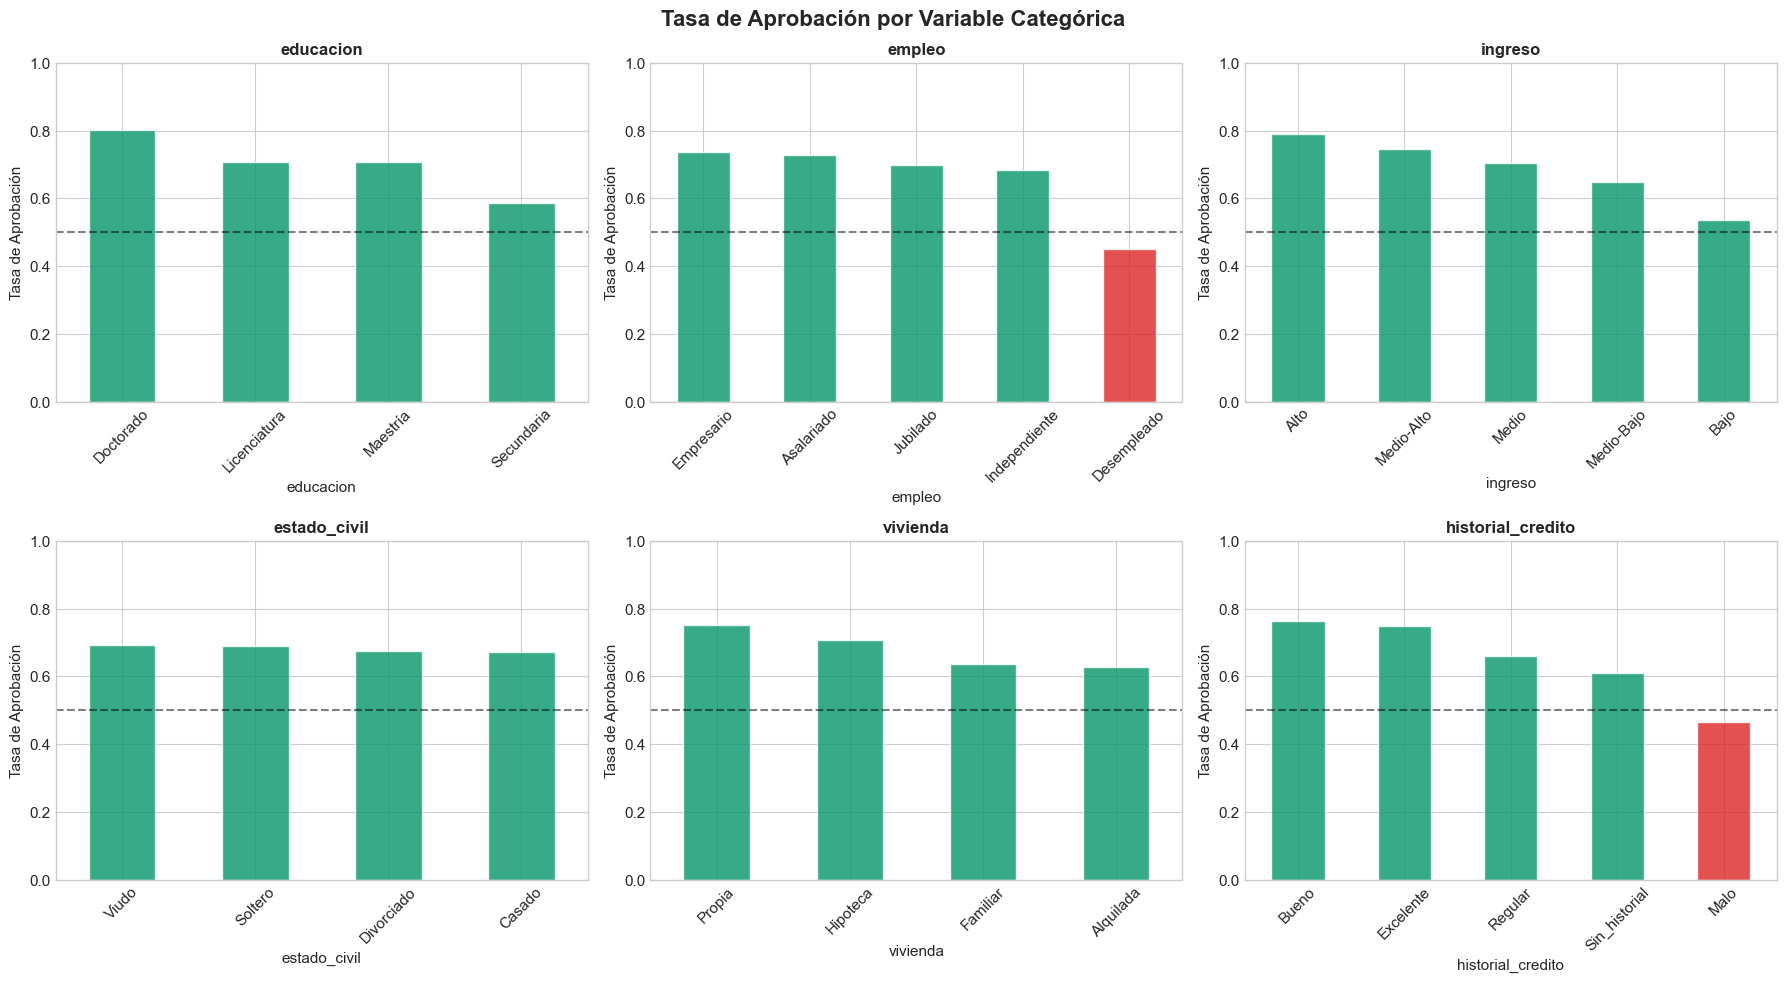


💡 Interpretación para el negocio:
   - Las variables con mayor poder predictivo son historial crediticio, ingreso y empleo
   - CategoricalNB captura estas relaciones directamente sin necesidad de One-Hot Encoding


In [20]:
# Visualización: Tasa de aprobación por categoría
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Tasa de Aprobación por Variable Categórica', fontsize=16, fontweight='bold')

for idx, col in enumerate(feature_cols_cred):
    ax = axes[idx // 3, idx % 3]
    rates = df_credito.groupby(col)['aprobado'].mean().sort_values(ascending=False)
    
    colors = [COLORS['success'] if r >= 0.5 else COLORS['danger'] for r in rates]
    rates.plot(kind='bar', ax=ax, color=colors, alpha=0.8, edgecolor='white')
    
    ax.axhline(y=0.5, color='black', linestyle='--', alpha=0.5)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_ylabel('Tasa de Aprobación')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\n💡 Interpretación para el negocio:")
print("   - Las variables con mayor poder predictivo son historial crediticio, ingreso y empleo")
print("   - CategoricalNB captura estas relaciones directamente sin necesidad de One-Hot Encoding")

---

## 5. Curvas ROC-AUC y Precision-Recall: Explicación Detallada

### 📊 ¿Qué son y por qué son fundamentales?

En clasificación binaria, elegir un **umbral de decisión** (threshold) genera un trade-off entre diferentes métricas. Las curvas ROC y Precision-Recall nos permiten **visualizar este trade-off completo** en lugar de evaluar el modelo con un solo umbral.

### 5.1 La Curva ROC (Receiver Operating Characteristic)

#### ¿Qué es?
La curva ROC grafica la **Tasa de Verdaderos Positivos (TPR, Recall)** vs. la **Tasa de Falsos Positivos (FPR)** para todos los umbrales posibles de decisión.

$$\text{TPR (Recall)} = \frac{\text{TP}}{\text{TP} + \text{FN}} \qquad \text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$

#### ¿Cómo interpretarla?

| Zona de la curva | Significado |
| :--- | :--- |
| Esquina superior izquierda (0, 1) | **Clasificador perfecto**: detecta todos los positivos sin falsos positivos |
| Diagonal (línea punteada) | **Clasificador aleatorio**: no tiene poder predictivo (AUC = 0.5) |
| Debajo de la diagonal | **Peor que aleatorio**: el modelo está invirtiendo las clases |

#### ¿Qué es el AUC (Area Under the Curve)?
El **AUC** es el área bajo la curva ROC. Mide la **probabilidad de que el modelo asigne un score más alto a un ejemplo positivo que a uno negativo**, seleccionados al azar:

$$\text{AUC} = P(\hat{p}(\text{positivo}) > \hat{p}(\text{negativo}))$$

| AUC | Interpretación |
| :--- | :--- |
| 0.9 – 1.0 | Excelente |
| 0.8 – 0.9 | Bueno |
| 0.7 – 0.8 | Aceptable |
| 0.6 – 0.7 | Pobre |
| 0.5 | Sin poder predictivo (aleatorio) |

In [21]:
# Entrenar múltiples modelos para comparar curvas
models = {
    'GaussianNB': GaussianNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5)
}

probas = {}
for name, model in models.items():
    if name in ['Logistic Regression', 'KNN (k=5)']:
        scaler = StandardScaler()
        X_tr_scaled = scaler.fit_transform(X_train)
        X_te_scaled = scaler.transform(X_test)
        model.fit(X_tr_scaled, y_train)
        probas[name] = model.predict_proba(X_te_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        probas[name] = model.predict_proba(X_test)[:, 1]

print("✅ Modelos entrenados. Procediendo a graficar curvas ROC...")

✅ Modelos entrenados. Procediendo a graficar curvas ROC...


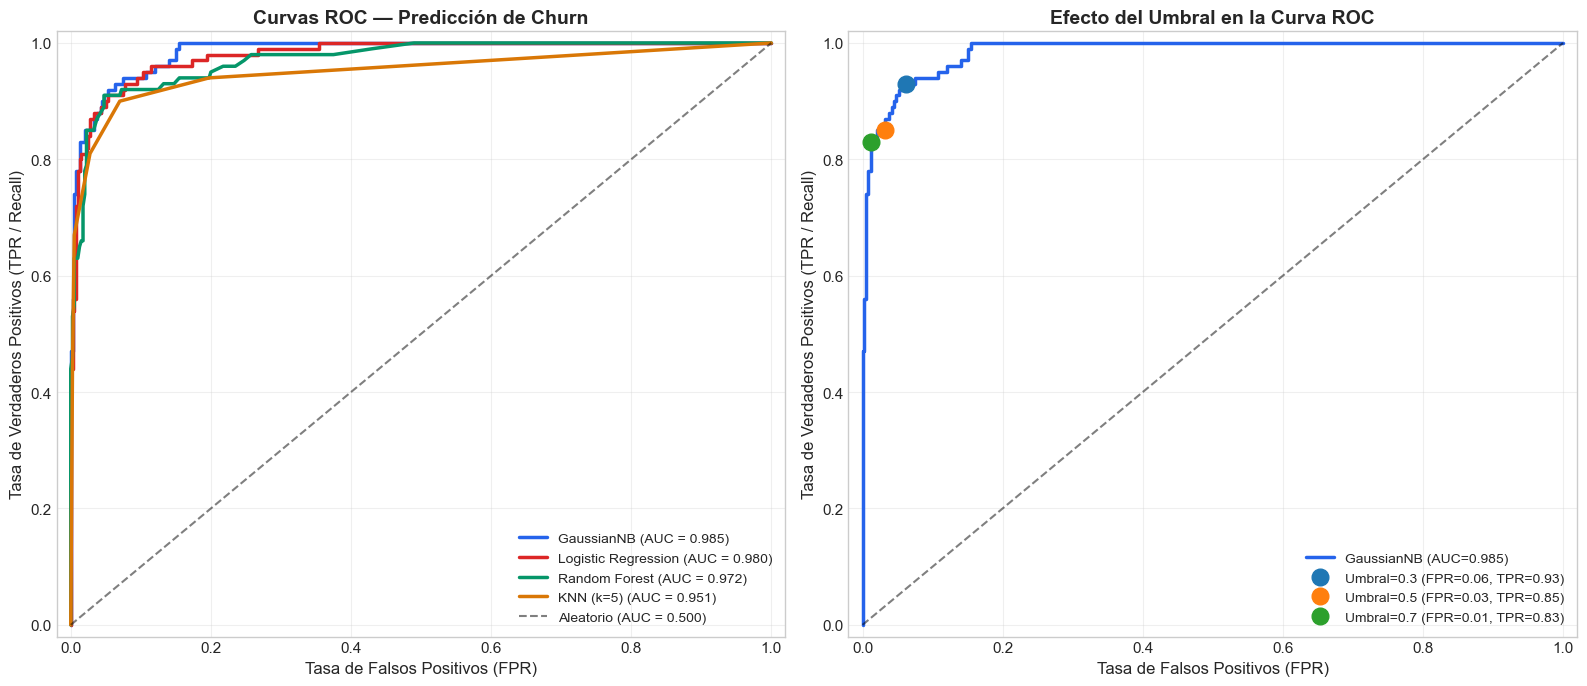


💡 Interpretación de la Curva ROC:
   - Cuanto más se acerca la curva a la esquina superior izquierda, MEJOR es el modelo
   - El AUC resume la curva en un solo número (0.5 = aleatorio, 1.0 = perfecto)
   - Un umbral BAJO (ej. 0.3) → más positivos detectados pero más falsos positivos
   - Un umbral ALTO (ej. 0.7) → menos falsos positivos pero se pierden positivos reales


In [22]:
# CURVA ROC DETALLADA CON MÚLTIPLES MODELOS
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors_list = [COLORS['primary'], COLORS['danger'], COLORS['success'], COLORS['warning']]

# Panel 1: Curvas ROC comparativas
ax = axes[0]
for (name, proba), color in zip(probas.items(), colors_list):
    fpr, tpr, thresholds = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2.5, label=f'{name} (AUC = {roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, alpha=0.5, label='Aleatorio (AUC = 0.500)')
ax.set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR / Recall)', fontsize=12)
ax.set_title('Curvas ROC — Predicción de Churn', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])

# Panel 2: Efecto del umbral
ax2 = axes[1]
fpr_gnb, tpr_gnb, thresholds_gnb = roc_curve(y_test, probas['GaussianNB'])
roc_auc_gnb = auc(fpr_gnb, tpr_gnb)

ax2.plot(fpr_gnb, tpr_gnb, color=COLORS['primary'], linewidth=2.5, label=f'GaussianNB (AUC={roc_auc_gnb:.3f})')
ax2.plot([0, 1], [0, 1], 'k--', linewidth=1.5, alpha=0.5)

for threshold_val in [0.3, 0.5, 0.7]:
    idx = np.argmin(np.abs(thresholds_gnb - threshold_val))
    ax2.plot(fpr_gnb[idx], tpr_gnb[idx], 'o', markersize=12, 
             label=f'Umbral={threshold_val:.1f} (FPR={fpr_gnb[idx]:.2f}, TPR={tpr_gnb[idx]:.2f})')

ax2.set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
ax2.set_ylabel('Tasa de Verdaderos Positivos (TPR / Recall)', fontsize=12)
ax2.set_title('Efecto del Umbral en la Curva ROC', fontsize=14, fontweight='bold')
ax2.legend(loc='lower right', fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.02])

plt.tight_layout()
plt.show()

print("\n💡 Interpretación de la Curva ROC:")
print("   - Cuanto más se acerca la curva a la esquina superior izquierda, MEJOR es el modelo")
print("   - El AUC resume la curva en un solo número (0.5 = aleatorio, 1.0 = perfecto)")
print("   - Un umbral BAJO (ej. 0.3) → más positivos detectados pero más falsos positivos")
print("   - Un umbral ALTO (ej. 0.7) → menos falsos positivos pero se pierden positivos reales")

### 5.2 La Curva Precision-Recall

#### ¿Qué es?
La curva Precision-Recall grafica la **Precisión** vs. el **Recall** para todos los umbrales posibles.

$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}} \qquad \text{Recall (TPR)} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

#### ¿Cuándo usar Precision-Recall en lugar de ROC?

| Situación | Usar ROC | Usar Precision-Recall |
| :--- | :---: | :---: |
| Clases balanceadas (50/50) | ✅ | ✅ |
| Clases desbalanceadas (ej. 95/5) | ❌ (engañosa) | ✅ (más informativa) |

**¿Por qué la ROC puede ser engañosa con datos desbalanceados?**  
Cuando la clase negativa es mucho más grande, el FPR se mantiene bajo incluso con muchos FP (porque el denominador TN + FP es enorme). La curva Precision-Recall NO sufre este problema porque no usa TN.

#### ¿Qué es el AP (Average Precision)?
El **AP** es el área bajo la curva Precision-Recall. A diferencia del AUC-ROC, el AP de un clasificador aleatorio **NO es 0.5**, sino aproximadamente igual a la prevalencia de la clase positiva:

$$\text{AP}_{\text{aleatorio}} \approx \frac{\text{Positivos}}{\text{Total}} = \text{Prevalencia}$$

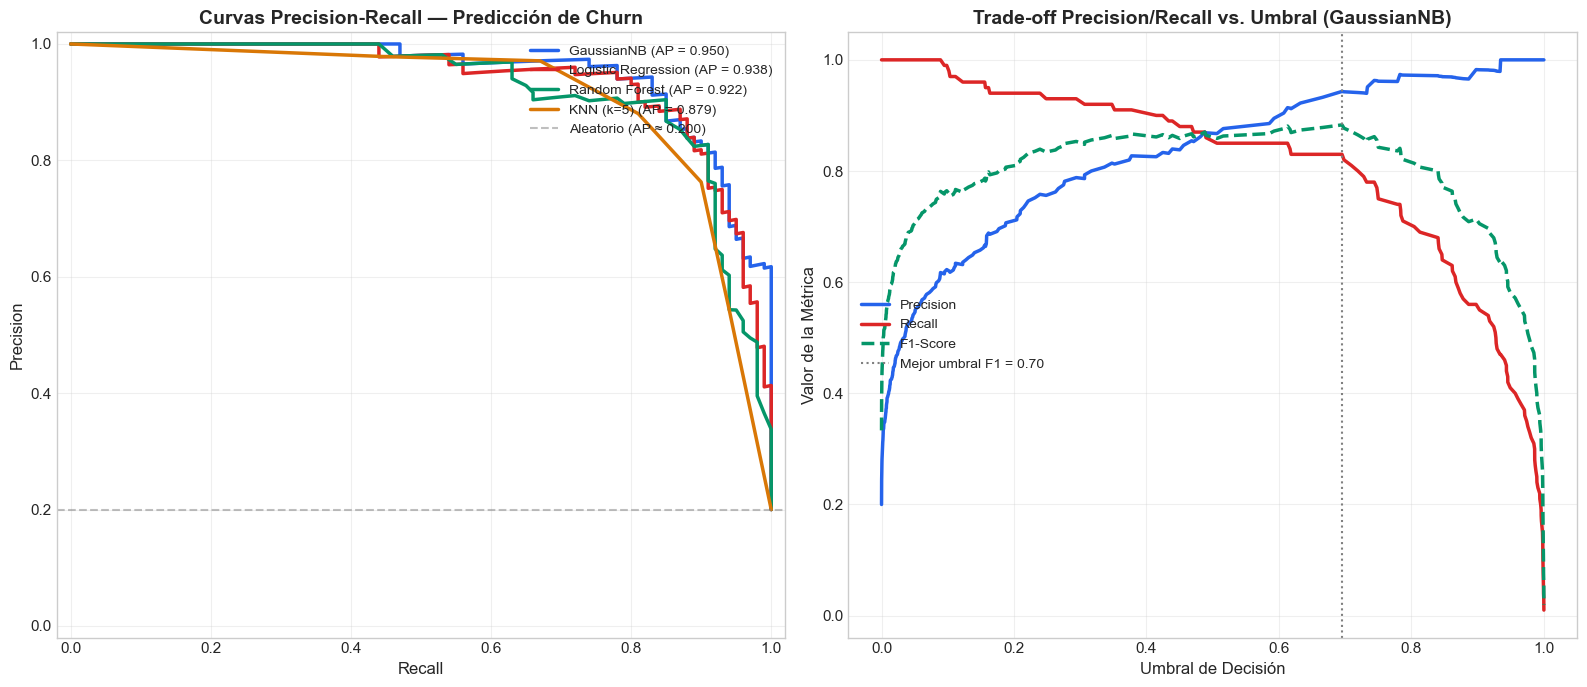


💡 Interpretación de la Curva Precision-Recall:
   - A medida que BAJA el umbral: el Recall SUBE pero la Precision BAJA
   - A medida que SUBE el umbral: la Precision SUBE pero el Recall BAJA
   - El F1-Score ayuda a encontrar el punto de equilibrio

   📌 Ejemplo práctico:
   En DETECCIÓN DE FRAUDE → priorizamos RECALL (no queremos perder fraudes)
   En FILTRO DE SPAM    → priorizamos PRECISION (no queremos perder emails legítimos)


In [23]:
# CURVA PRECISION-RECALL DETALLADA
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax = axes[0]
for (name, proba), color in zip(probas.items(), colors_list):
    precision, recall, thresholds = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    ax.plot(recall, precision, color=color, linewidth=2.5, label=f'{name} (AP = {ap:.3f})')

prevalence = y_test.mean()
ax.axhline(y=prevalence, color='gray', linestyle='--', linewidth=1.5, alpha=0.5, 
           label=f'Aleatorio (AP ≈ {prevalence:.3f})')
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Curvas Precision-Recall — Predicción de Churn', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])

# Panel 2: Trade-off Precision vs Recall vs Umbral
ax2 = axes[1]
precision_gnb, recall_gnb, thresholds_pr = precision_recall_curve(y_test, probas['GaussianNB'])

ax2.plot(thresholds_pr, precision_gnb[:-1], color=COLORS['primary'], linewidth=2.5, label='Precision')
ax2.plot(thresholds_pr, recall_gnb[:-1], color=COLORS['danger'], linewidth=2.5, label='Recall')

f1_scores = 2 * (precision_gnb[:-1] * recall_gnb[:-1]) / (precision_gnb[:-1] + recall_gnb[:-1] + 1e-10)
ax2.plot(thresholds_pr, f1_scores, color=COLORS['success'], linewidth=2.5, linestyle='--', label='F1-Score')

best_f1_idx = np.argmax(f1_scores)
ax2.axvline(x=thresholds_pr[best_f1_idx], color='gray', linestyle=':', linewidth=1.5,
            label=f'Mejor umbral F1 = {thresholds_pr[best_f1_idx]:.2f}')

ax2.set_xlabel('Umbral de Decisión', fontsize=12)
ax2.set_ylabel('Valor de la Métrica', fontsize=12)
ax2.set_title('Trade-off Precision/Recall vs. Umbral (GaussianNB)', fontsize=14, fontweight='bold')
ax2.legend(loc='center left', fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 Interpretación de la Curva Precision-Recall:")
print("   - A medida que BAJA el umbral: el Recall SUBE pero la Precision BAJA")
print("   - A medida que SUBE el umbral: la Precision SUBE pero el Recall BAJA")
print("   - El F1-Score ayuda a encontrar el punto de equilibrio")
print("\n   📌 Ejemplo práctico:")
print("   En DETECCIÓN DE FRAUDE → priorizamos RECALL (no queremos perder fraudes)")
print("   En FILTRO DE SPAM    → priorizamos PRECISION (no queremos perder emails legítimos)")

### 5.3 ROC vs Precision-Recall en Datos Desbalanceados

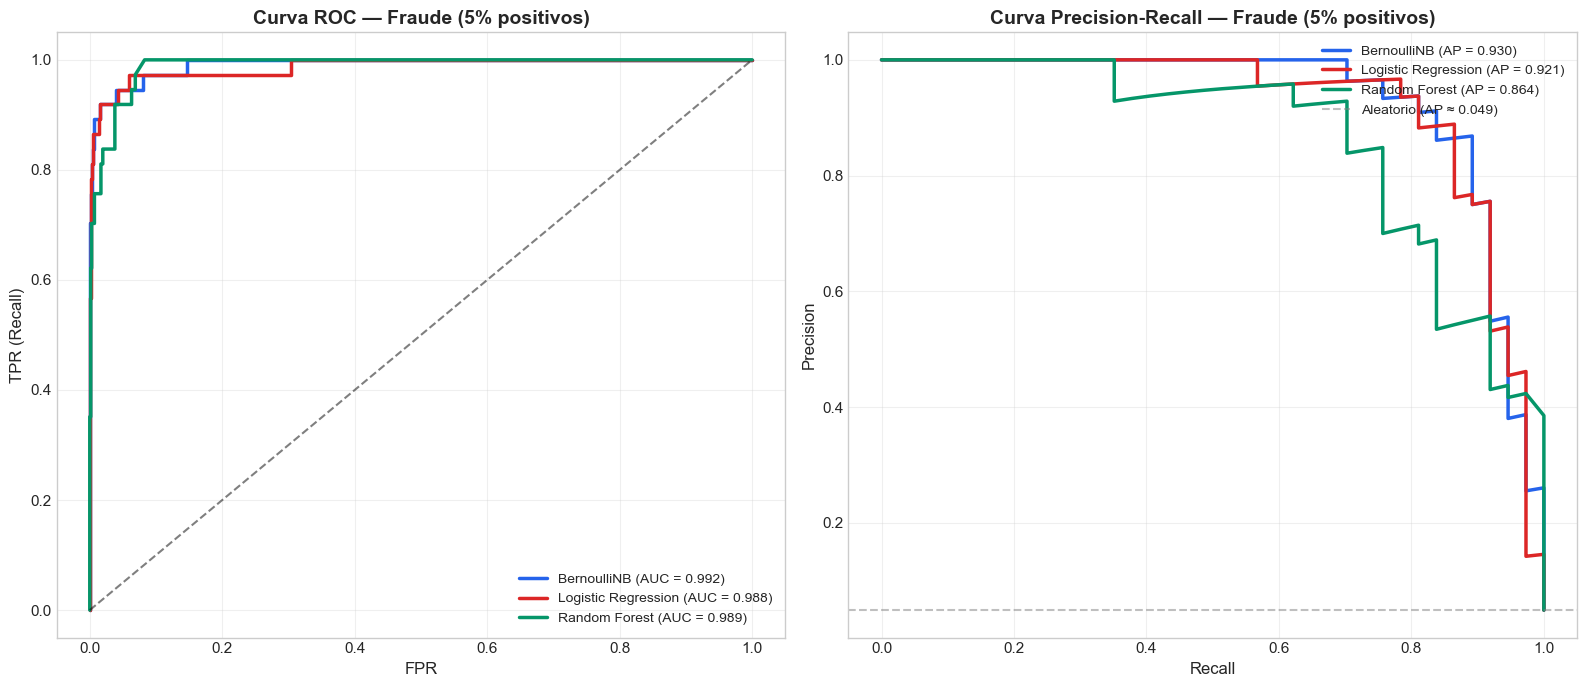


💡 Conclusión clave:
   - Con datos DESBALANCEADOS, las curvas ROC se ven 'bien' para TODOS los modelos
   - Pero la curva Precision-Recall revela diferencias REALES en capacidad de detección
   - REGLA: Si la clase positiva es < 20% del total → prefiere Precision-Recall


In [24]:
# Demostración con datos desbalanceados (fraude: 95/5)
models_fraud = {
    'BernoulliNB': BernoulliNB(alpha=1.0),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}

probas_fraud = {}
for name, model in models_fraud.items():
    model.fit(X_fr_train, y_fr_train)
    probas_fraud[name] = model.predict_proba(X_fr_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ROC
ax = axes[0]
for (name, proba), color in zip(probas_fraud.items(), colors_list[:3]):
    fpr, tpr, _ = roc_curve(y_fr_test, proba)
    roc_auc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2.5, label=f'{name} (AUC = {roc_auc_val:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, alpha=0.5)
ax.set_title('Curva ROC — Fraude (5% positivos)', fontsize=14, fontweight='bold')
ax.set_xlabel('FPR', fontsize=12)
ax.set_ylabel('TPR (Recall)', fontsize=12)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)

# Precision-Recall
ax2 = axes[1]
for (name, proba), color in zip(probas_fraud.items(), colors_list[:3]):
    precision, recall, _ = precision_recall_curve(y_fr_test, proba)
    ap = average_precision_score(y_fr_test, proba)
    ax2.plot(recall, precision, color=color, linewidth=2.5, label=f'{name} (AP = {ap:.3f})')

prevalence_fraud = y_fr_test.mean()
ax2.axhline(y=prevalence_fraud, color='gray', linestyle='--', linewidth=1.5, alpha=0.5,
            label=f'Aleatorio (AP ≈ {prevalence_fraud:.3f})')
ax2.set_title('Curva Precision-Recall — Fraude (5% positivos)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Recall', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.legend(loc='upper right', fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 Conclusión clave:")
print("   - Con datos DESBALANCEADOS, las curvas ROC se ven 'bien' para TODOS los modelos")
print("   - Pero la curva Precision-Recall revela diferencias REALES en capacidad de detección")
print("   - REGLA: Si la clase positiva es < 20% del total → prefiere Precision-Recall")

---

## 6. Benchmark Integral: Naive Bayes vs. Otros Modelos

Comparación multi-dimensional evaluando calidad predictiva, velocidad de entrenamiento e inferencia.

In [25]:
# BENCHMARK COMPLETO
benchmark_models = {
    'GaussianNB': GaussianNB(),
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'KNN (k=5)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}

sizes = [200, 500, 1000, 2000, 5000]
results_benchmark = []

for n in sizes:
    df_temp = generar_dataset_churn(n_samples=n, random_state=42)
    X_temp = df_temp.drop('churn', axis=1).values
    y_temp = df_temp['churn'].values
    
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
    )
    
    for name, model in benchmark_models.items():
        t0 = time.time()
        model.fit(X_tr, y_tr)
        t_fit = (time.time() - t0) * 1000
        
        t0 = time.time()
        y_pred = model.predict(X_te)
        y_prob = model.predict_proba(X_te)[:, 1]
        t_pred = (time.time() - t0) * 1000
        
        results_benchmark.append({
            'Modelo': name, 'N_samples': n,
            'Accuracy': accuracy_score(y_te, y_pred),
            'F1-Score': f1_score(y_te, y_pred),
            'ROC-AUC': roc_auc_score(y_te, y_prob),
            'Train_ms': t_fit, 'Predict_ms': t_pred
        })

df_benchmark = pd.DataFrame(results_benchmark)
print("✅ Benchmark completado.")

✅ Benchmark completado.


In [26]:
# Tabla resumen para N=2000
print("📊 Resultados del Benchmark (N = 2000):")
display(
    df_benchmark[df_benchmark['N_samples'] == 2000]
    .set_index('Modelo')
    .drop('N_samples', axis=1)
    .round(4)
)

📊 Resultados del Benchmark (N = 2000):


,Accuracy,F1-Score,ROC-AUC,Train_ms,Predict_ms
Modelo,,,,,
GaussianNB,0.944,0.8586,0.9850,0.9224,0.7401
Logistic Regression,0.944,0.8542,0.9796,5.9388,1.2622
KNN (k=5),0.940,0.8438,0.9507,4.1769,28.7497
Decision Tree,0.890,0.7317,0.8581,18.3630,0.7377
Random Forest,0.946,0.8586,0.9715,451.5009,18.2099


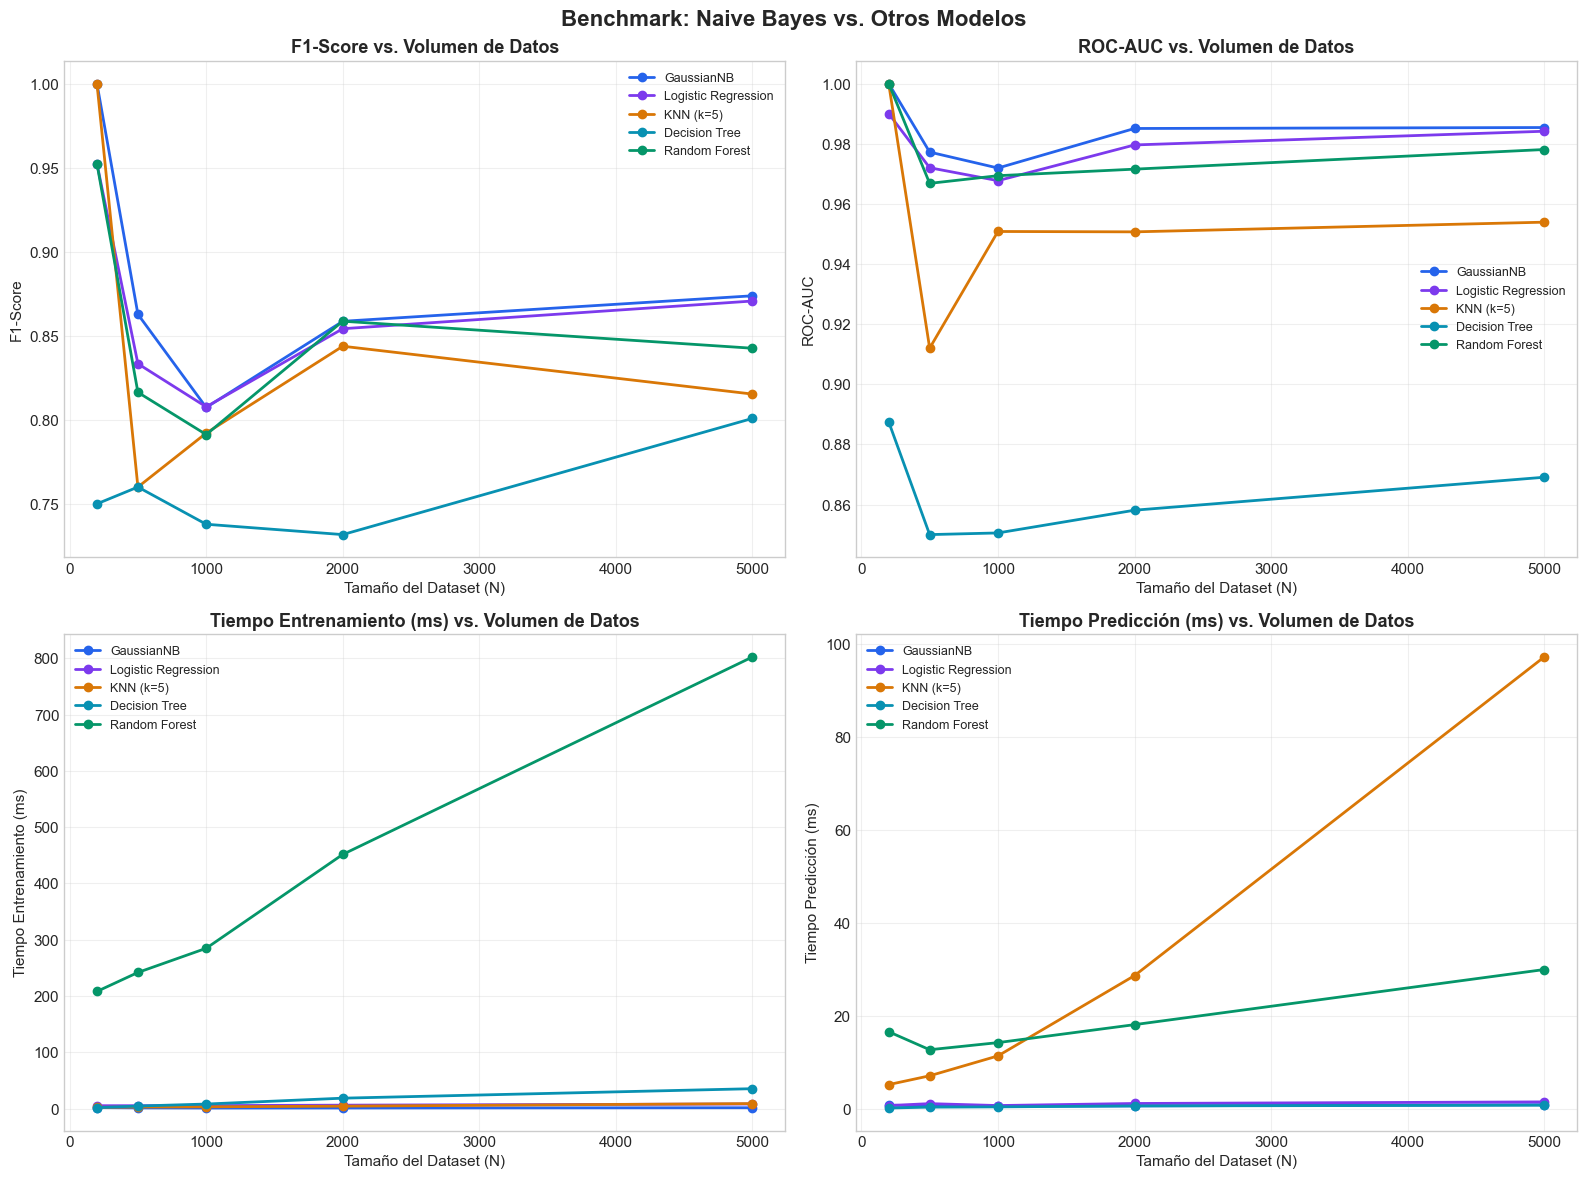


💡 Conclusiones del Benchmark:
   1. GaussianNB es SIGNIFICATIVAMENTE más rápido en entrenamiento e inferencia
   2. Con pocos datos (N < 500), NB puede ser COMPETITIVO con modelos más complejos
   3. A medida que N crece, modelos como Random Forest suelen superar a NB
   4. NB es ideal como BASELINE o cuando la latencia es crítica


In [27]:
# VISUALIZACIONES DEL BENCHMARK
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Benchmark: Naive Bayes vs. Otros Modelos', fontsize=16, fontweight='bold')

model_colors = {
    'GaussianNB': COLORS['primary'],
    'Logistic Regression': COLORS['secondary'],
    'KNN (k=5)': COLORS['warning'],
    'Decision Tree': COLORS['info'],
    'Random Forest': COLORS['success']
}

metrics = [('F1-Score', 'F1-Score'), ('ROC-AUC', 'ROC-AUC'), ('Train_ms', 'Tiempo Entrenamiento (ms)'), ('Predict_ms', 'Tiempo Predicción (ms)')]

for ax_idx, (col, ylabel) in enumerate(metrics):
    ax = axes[ax_idx // 2, ax_idx % 2]
    for model_name in benchmark_models.keys():
        data = df_benchmark[df_benchmark['Modelo'] == model_name]
        ax.plot(data['N_samples'], data[col], 'o-', 
                color=model_colors[model_name], linewidth=2, markersize=6, label=model_name)
    ax.set_xlabel('Tamaño del Dataset (N)', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(ylabel + ' vs. Volumen de Datos', fontsize=13, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 Conclusiones del Benchmark:")
print("   1. GaussianNB es SIGNIFICATIVAMENTE más rápido en entrenamiento e inferencia")
print("   2. Con pocos datos (N < 500), NB puede ser COMPETITIVO con modelos más complejos")
print("   3. A medida que N crece, modelos como Random Forest suelen superar a NB")
print("   4. NB es ideal como BASELINE o cuando la latencia es crítica")

### 6.1 Benchmark en Datos de Texto (NLP)

In [28]:
# Benchmark NLP
nlp_models = {
    'MultinomialNB': Pipeline([
        ('vec', TfidfVectorizer(max_features=5000)),
        ('clf', MultinomialNB(alpha=1.0))
    ]),
    'ComplementNB': Pipeline([
        ('vec', TfidfVectorizer(max_features=5000)),
        ('clf', ComplementNB(alpha=1.0))
    ]),
    'BernoulliNB': Pipeline([
        ('vec', TfidfVectorizer(max_features=5000, binary=True)),
        ('clf', BernoulliNB(alpha=1.0))
    ]),
    'Logistic Regression': Pipeline([
        ('vec', TfidfVectorizer(max_features=5000)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
}

results_nlp_bench = {}
for name, pipe in nlp_models.items():
    t0 = time.time()
    pipe.fit(emails_train, y_spam_train)
    t_fit = (time.time() - t0) * 1000
    
    t0 = time.time()
    y_pred = pipe.predict(emails_test)
    y_prob = pipe.predict_proba(emails_test)[:, 1]
    t_pred = (time.time() - t0) * 1000
    
    results_nlp_bench[name] = {
        'Accuracy': accuracy_score(y_spam_test, y_pred),
        'F1-Score': f1_score(y_spam_test, y_pred),
        'ROC-AUC': roc_auc_score(y_spam_test, y_prob),
        'Train_ms': round(t_fit, 2),
        'Predict_ms': round(t_pred, 2)
    }

df_nlp_bench = pd.DataFrame(results_nlp_bench).T
print("📊 Benchmark NLP — Clasificación de Spam:")
display(df_nlp_bench.round(4))

print("\n💡 Nota sobre ComplementNB:")
print("   ComplementNB fue diseñado para datos DESBALANCEADOS.")
print("   Modela P(X|Y≠k) en lugar de P(X|Y=k) y luego invierte.")

📊 Benchmark NLP — Clasificación de Spam:


,Accuracy,F1-Score,ROC-AUC,Train_ms,Predict_ms
MultinomialNB,1.0,1.0,1.0,28.57,15.24
ComplementNB,1.0,1.0,1.0,24.01,15.89
BernoulliNB,1.0,1.0,1.0,22.50,18.60
Logistic Regression,1.0,1.0,1.0,29.06,14.61



💡 Nota sobre ComplementNB:
   ComplementNB fue diseñado para datos DESBALANCEADOS.
   Modela P(X|Y≠k) en lugar de P(X|Y=k) y luego invierte.


---

## 7. Guía Práctica de Selección: ¿Cuándo Usar Cada Variante de Naive Bayes?

### 🗺️ Mapa de Decisión

```
¿Qué tipo de datos tienes?
│
├── NUMÉRICOS CONTINUOS (edad, saldo, temperatura...)
│   └── GaussianNB ✅ (aplicar PowerTransformer si no son normales)
│
├── TEXTO / CONTEOS DE PALABRAS
│   ├── Clases BALANCEADAS → MultinomialNB
│   ├── Clases DESBALANCEADAS → ComplementNB ✅
│   └── Textos CORTOS (tweets, SMS) → BernoulliNB ✅
│
├── BINARIOS (sí/no, 0/1)
│   └── BernoulliNB ✅
│
└── CATEGÓRICOS (nivel educativo, ciudad...)
    └── CategoricalNB ✅
```

### 📋 Tabla de Referencia Rápida

| Variante | Tipo de Dato | Hiperparámetro Clave | Cuándo Brilla | Cuándo NO Usar |
| :--- | :--- | :--- | :--- | :--- |
| **GaussianNB** | Continuos | `var_smoothing` | Baseline rápido, pocos datos | Features no-normales |
| **MultinomialNB** | Conteos (≥0) | `alpha` | Clasificación de texto (BoW/TF-IDF) | Features negativas |
| **BernoulliNB** | Binarios {0,1} | `alpha`, `binarize` | Textos cortos, features binarias | Conteos > 1 |
| **ComplementNB** | Conteos (≥0) | `alpha` | Texto con clases desbalanceadas | Datos balanceados |
| **CategoricalNB** | Categóricos | `alpha` | Datos tabulares categóricos | Datos numéricos |

### ⚡ Ventajas y Limitaciones de Naive Bayes

| Ventaja | Limitación |
| :--- | :--- |
| Velocidad extrema (ms) | Asunción de independencia poco realista |
| Eficiencia muestral (pocos datos) | Probabilidades sobreconfiadas |
| `partial_fit` para streaming | Fronteras lineales/cuadráticas simples |
| Interpretabilidad total | Sensible a la distribución de los datos |

🏆 RESUMEN FINAL — Todas las Variantes de Naive Bayes en Acción:


,Caso de Uso,Variante NB,F1-Score,Accuracy,ROC-AUC
0,Churn Bancario (Continuos),GaussianNB,0.8586,0.944,0.9850
1,Spam Email (Texto),MultinomialNB,1.0000,1.000,1.0000
2,Fraude (Binarios),BernoulliNB,0.8696,0.988,0.9917
3,Crédito (Categóricos),CategoricalNB,0.7951,0.688,0.6719


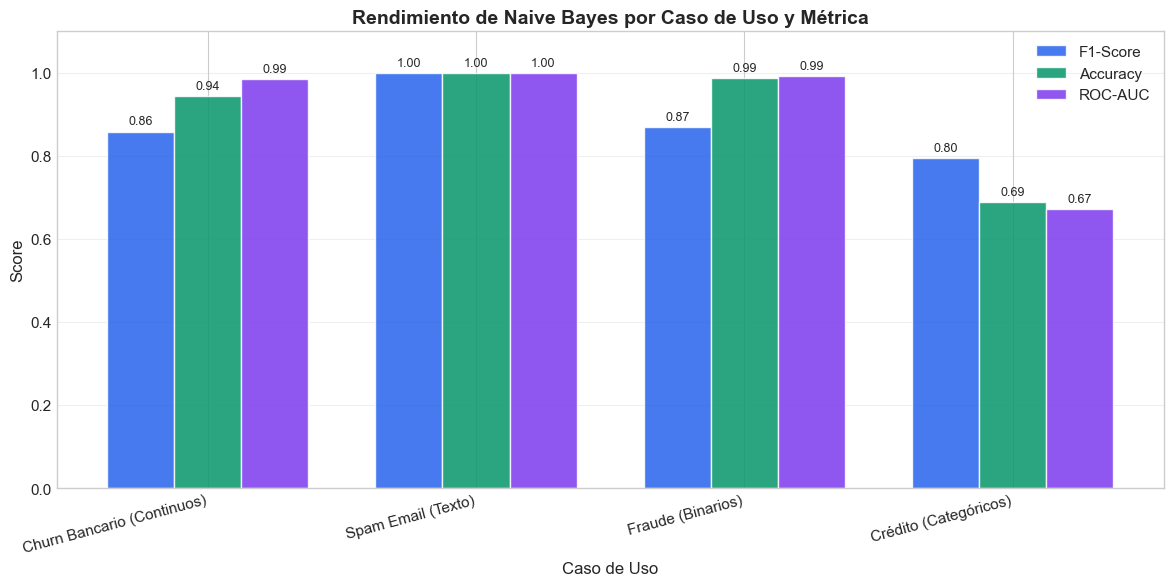

In [29]:
# RESUMEN VISUAL FINAL
resumen_final = pd.DataFrame({
    'Caso de Uso': [
        'Churn Bancario (Continuos)',
        'Spam Email (Texto)',
        'Fraude (Binarios)',
        'Crédito (Categóricos)'
    ],
    'Variante NB': ['GaussianNB', 'MultinomialNB', 'BernoulliNB', 'CategoricalNB'],
    'F1-Score': [
        f1_score(y_test, gnb.predict(X_test)),
        f1_score(y_spam_test, pipe_count.predict(emails_test)),
        f1_score(y_fr_test, bnb.predict(X_fr_test)),
        f1_score(y_cr_test, cnb.predict(X_cr_test)),
    ],
    'Accuracy': [
        accuracy_score(y_test, gnb.predict(X_test)),
        accuracy_score(y_spam_test, pipe_count.predict(emails_test)),
        accuracy_score(y_fr_test, bnb.predict(X_fr_test)),
        accuracy_score(y_cr_test, cnb.predict(X_cr_test)),
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, gnb.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_spam_test, pipe_count.predict_proba(emails_test)[:, 1]),
        roc_auc_score(y_fr_test, bnb.predict_proba(X_fr_test)[:, 1]),
        roc_auc_score(y_cr_test, cnb.predict_proba(X_cr_test)[:, 1]),
    ]
})

print("🏆 RESUMEN FINAL — Todas las Variantes de Naive Bayes en Acción:")
print("="*80)
display(resumen_final.round(4))

# Visualización final
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(resumen_final))
width = 0.25

bars1 = ax.bar(x - width, resumen_final['F1-Score'], width, label='F1-Score', 
               color=COLORS['primary'], alpha=0.85, edgecolor='white')
bars2 = ax.bar(x, resumen_final['Accuracy'], width, label='Accuracy', 
               color=COLORS['success'], alpha=0.85, edgecolor='white')
bars3 = ax.bar(x + width, resumen_final['ROC-AUC'], width, label='ROC-AUC', 
               color=COLORS['secondary'], alpha=0.85, edgecolor='white')

ax.set_xlabel('Caso de Uso', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Rendimiento de Naive Bayes por Caso de Uso y Métrica', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(resumen_final['Caso de Uso'], rotation=15, ha='right')
ax.legend(fontsize=11)
ax.set_ylim(0, 1.1)
ax.grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

---

## 📌 Conclusiones y Mejores Prácticas

### Lo que debes recordar de este cuaderno:

1. **Naive Bayes NO es un solo modelo**, sino una **familia** de clasificadores para diferentes tipos de datos.

2. **El modelo correcto para el dato correcto:**
   - Datos continuos → `GaussianNB`
   - Conteos/texto → `MultinomialNB` o `ComplementNB` (si está desbalanceado)
   - Datos binarios → `BernoulliNB`
   - Datos categóricos → `CategoricalNB`

3. **ROC-AUC vs. Precision-Recall:**
   - Datos balanceados → Ambas curvas son informativas
   - Datos desbalanceados → **Precision-Recall es más informativa**

4. **Naive Bayes es ideal como BASELINE profesional:** Rápido, simple, interpretable.

5. **La asunción de independencia es "ingenua" pero sorprendentemente efectiva** en muchos escenarios reales.

---

*Notebook desarrollado como parte del módulo `05_Naive_Bayes` del Curso de Machine Learning 501.*